In [1]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
import re
from datetime import timedelta
from img2table.document import Image
from img2table.ocr import TesseractOCR
from openpyxl.styles import Alignment
from openpyxl.utils import get_column_letter
from openpyxl.workbook import Workbook
from PIL import Image as PILImage
from textdistance import damerau_levenshtein
from time import time

os.environ["PATH"] += os.pathsep + r"C:\Program Files\Tesseract-OCR"
ocr = TesseractOCR(lang="rus+eng", psm=11)

tables_folder = "./tables"
screenshots_folder = "./screenshots"
results_folder = "./results_1"

image_paths = [f"{screenshots_folder}/{image_name}" for image_name in os.listdir(screenshots_folder)]

pd.set_option("display.max_colwidth", None)

In [ ]:
def show_image(image_path):
    print(f"Изображение: {image_path}")
    plt.figure(figsize=(12, 12))
    image = PILImage.open(image_path)
    plt.imshow(image)
    plt.axis("off")
    plt.show()

def recognize_table(image_path):
    image = Image(image_path)

    start_time = time()
    tables = image.extract_tables(
        ocr=ocr,
        implicit_rows=False,
        implicit_columns=False,
        borderless_tables=False,
        min_confidence=50,
    )
    end_time = time()
    elapsed_time = end_time - start_time

    if not tables:
        return pd.DataFrame(), None, elapsed_time
    
    table = tables[0]
    df = table.df
    
    return df, table, elapsed_time

def show_extracted_table(image_path, table):
    print("Изображение с обнаруженной таблицей:")
    image = PILImage.open(image_path)

    plt.figure(figsize=(12, 12))
    ax = plt.gca()
    ax.axis("off")
    ax.imshow(image)
    
    for row_cells in table.content.values():
        for cell in row_cells:
            cell_bbox = cell.bbox
            x1, y1, x2, y2 = cell_bbox.x1, cell_bbox.y1, cell_bbox.x2, cell_bbox.y2
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor="red", facecolor="none",
            )
            ax.add_patch(rect)
    
    plt.show()

def pad_to_same_size(df1, df2):
    max_rows = max(df1.shape[0], df2.shape[0])
    max_cols = max(df1.shape[1], df2.shape[1])
    
    df1_padded = pd.DataFrame("", index=range(max_rows), columns=range(max_cols))
    df2_padded = pd.DataFrame("", index=range(max_rows), columns=range(max_cols))
    
    df1_padded.iloc[:df1.shape[0], :df1.shape[1]] = df1.values
    df2_padded.iloc[:df2.shape[0], :df2.shape[1]] = df2.values
    
    return df1_padded, df2_padded

def evaluate(table_true_path, table_pred_path):
    df_true = pd.read_csv(table_true_path, sep=";", dtype=str, encoding="utf-8-sig").fillna("")
    df_pred = pd.read_excel(table_pred_path, header=None, dtype=str).fillna("")
    
    df_true, df_pred = pad_to_same_size(df_true, df_pred)
    
    total_true_chars = 0
    total_distance = 0
    
    for i in range(df_true.shape[0]):
        for j in range(df_true.shape[1]):
            s_true = df_true.iloc[i, j]
            s_pred = df_pred.iloc[i, j]
            
            s_true = re.sub(r"\s+", "", s_true)
            s_pred = re.sub(r"\s+", "", s_pred)
            
            total_true_chars += len(s_true)
            total_distance += damerau_levenshtein(s_true, s_pred)
    
    accuracy = 1 - total_distance / total_true_chars
    
    return total_distance, accuracy

def save_table_to_excel(df, filepath, column_width=30):
    wb = Workbook()
    ws = wb.active
    for _, row in df.iterrows():
        ws.append(row.to_list())
    
    for i in range(1, df.shape[1] + 1):
        ws.column_dimensions[get_column_letter(i)].width = column_width
    
    cell_alignment = Alignment(vertical="center", wrap_text=True)
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = cell_alignment
    
    if os.path.exists(filepath):
        os.remove(filepath)
    
    wb.save(filepath)
    print(f"Распознанная таблица сохранена в {filepath}")

def test_on_image(image_path, verbose=0, save_to_excel=True):
    if verbose:
        show_image(image_path)

    df, table, elapsed_time = recognize_table(image_path)
    elapsed_time_str = f"{elapsed_time:.3f}"
    
    if df.empty:
        print(f"На изображении {image_path} таблица не найдена (время: {elapsed_time_str} секунд)")
        return elapsed_time
    
    if save_to_excel:
        result_path = image_path.replace(screenshots_folder, results_folder).replace(".png", ".xlsx")

    if verbose:
        show_extracted_table(image_path, table)
        if save_to_excel:
            save_table_to_excel(df, result_path)
            table_true_name = re.search(r"(table_\d+)", image_path).group(1)
            total_distance, accuracy = evaluate(
                table_true_path=f"{tables_folder}/{table_true_name}.csv",
                table_pred_path=result_path,
            )
            print(
                f"Затраченное время: {elapsed_time_str} секунд\n"
                f"Всего ошибок: {total_distance}\n"
                f"Точность распознавания: {accuracy:.3f}"
            )
        else:
            print(f"Распознанная таблица (время: {elapsed_time_str} секунд):")
        display(df)
    else:
        print(f"На изображении {image_path} таблица распознана за {elapsed_time_str} секунд")
        if save_to_excel:
            save_table_to_excel(df, result_path)

    return elapsed_time

def test_on_grouped_images(image_paths, group_size=4, reverse=False, verbose=0, save_to_excel=False):
    n = len(image_paths)
    if reverse:
        image_indices = []
        for start in range(0, n, group_size):
            group = list(range(start, min(start + group_size, n)))
            image_indices.extend(group[::-1])

    elapsed_time = 0
    for i in image_indices:
        elapsed_time += test_on_image(image_paths[i], verbose=verbose, save_to_excel=save_to_excel)
        print("", "-" * 100, "", sep="\n")
    elapsed_time_str = str(timedelta(seconds=round(elapsed_time)))
    print(f"Суммарное время распознавания {n} таблиц: {elapsed_time_str}")

Изображение: ./screenshots/table_1_base_160.png


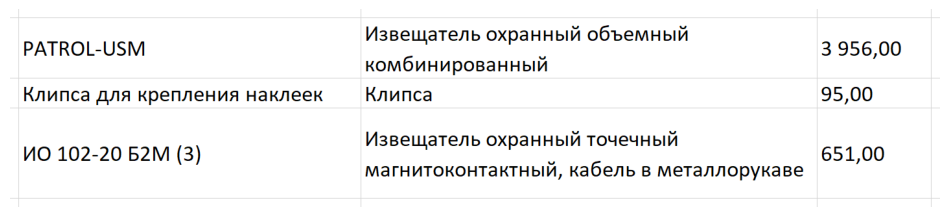

Изображение с обнаруженной таблицей:


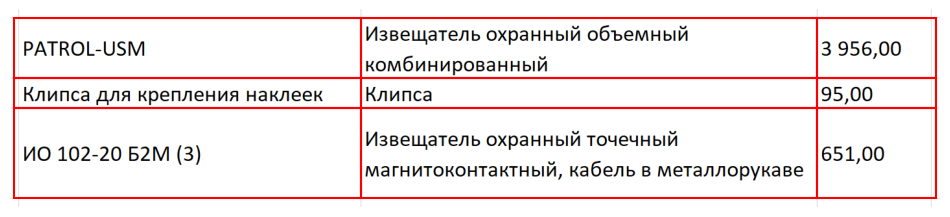

Распознанная таблица сохранена в ./results_1/table_1_base_160.xlsx
Затраченное время: 0.614 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_130.png


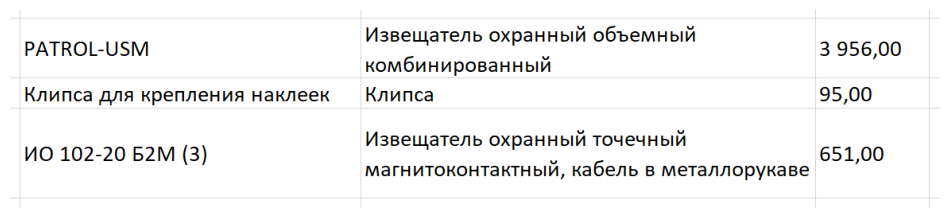

Изображение с обнаруженной таблицей:


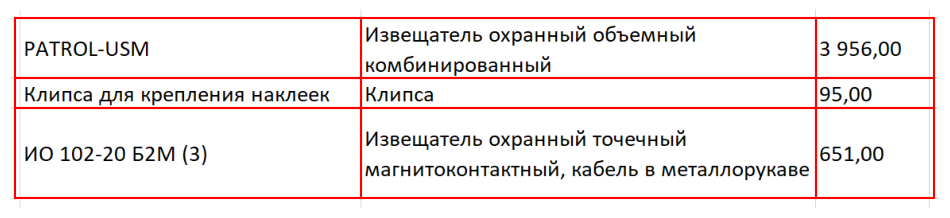

Распознанная таблица сохранена в ./results_1/table_1_base_130.xlsx
Затраченное время: 0.504 секунд
Всего ошибок: 4
Точность распознавания: 0.978


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",‚00



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_100.png


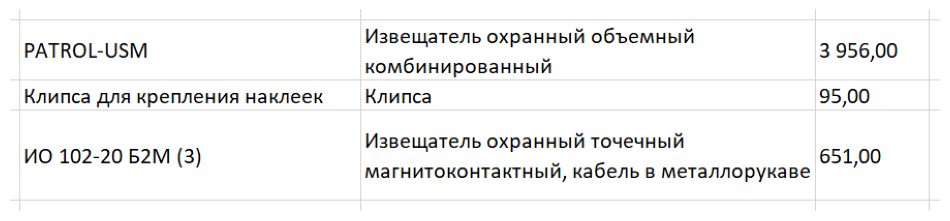

Изображение с обнаруженной таблицей:


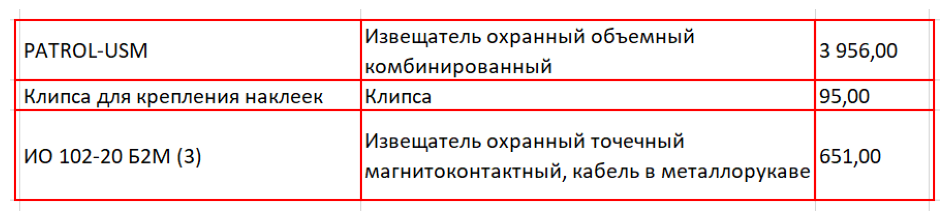

Распознанная таблица сохранена в ./results_1/table_1_base_100.xlsx
Затраченное время: 0.453 секунд
Всего ошибок: 4
Точность распознавания: 0.978


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",‚00



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_070.png


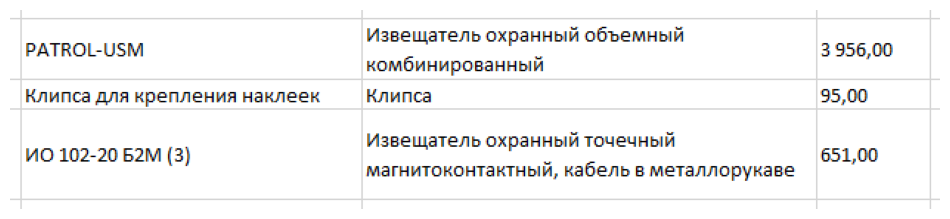

Изображение с обнаруженной таблицей:


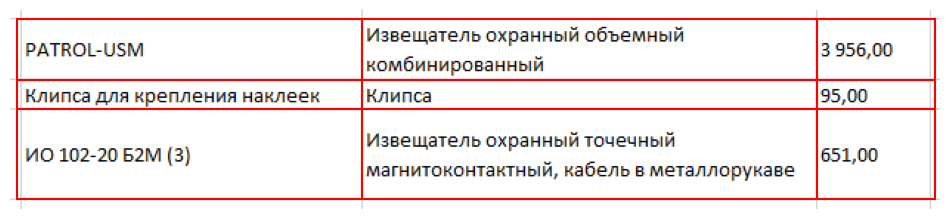

Распознанная таблица сохранена в ./results_1/table_1_base_070.xlsx
Затраченное время: 0.421 секунд
Всего ошибок: 10
Точность распознавания: 0.944


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"35,00"
2,MMO 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",",00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_160.png


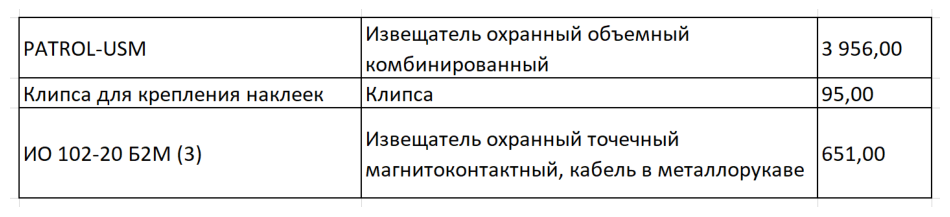

Изображение с обнаруженной таблицей:


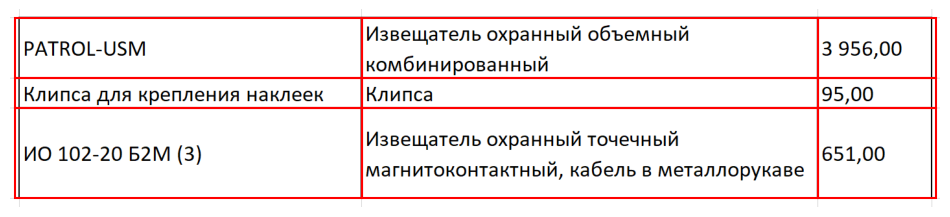

Распознанная таблица сохранена в ./results_1/table_1_base_contrast_160.xlsx
Затраченное время: 0.511 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_130.png


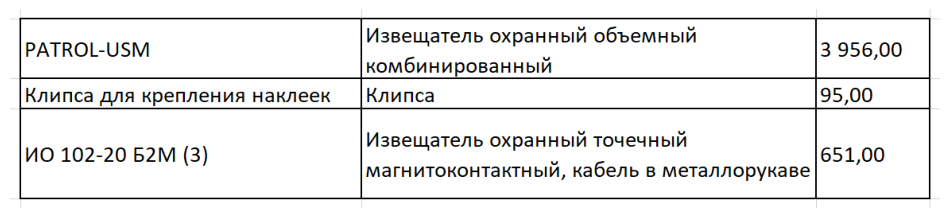

Изображение с обнаруженной таблицей:


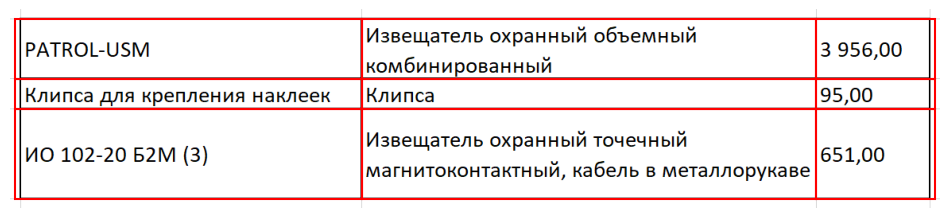

Распознанная таблица сохранена в ./results_1/table_1_base_contrast_130.xlsx
Затраченное время: 0.772 секунд
Всего ошибок: 1
Точность распознавания: 0.994


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","51,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_100.png


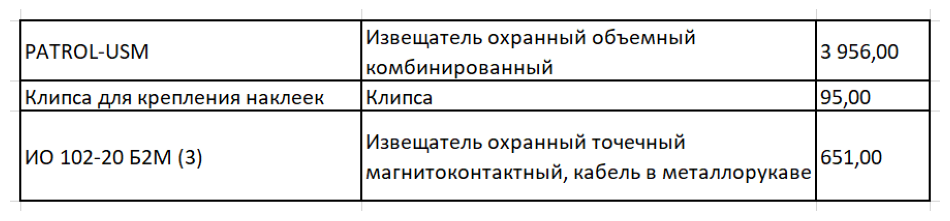

Изображение с обнаруженной таблицей:


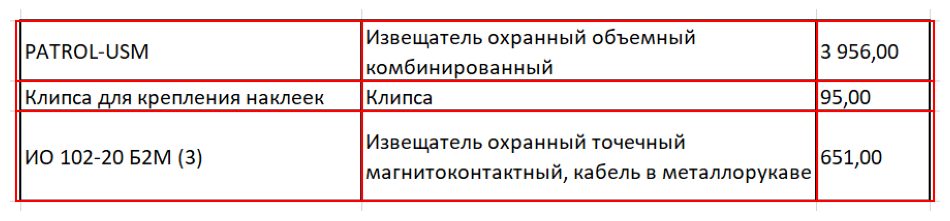

Распознанная таблица сохранена в ./results_1/table_1_base_contrast_100.xlsx
Затраченное время: 0.566 секунд
Всего ошибок: 4
Точность распознавания: 0.978


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",‚00



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_070.png


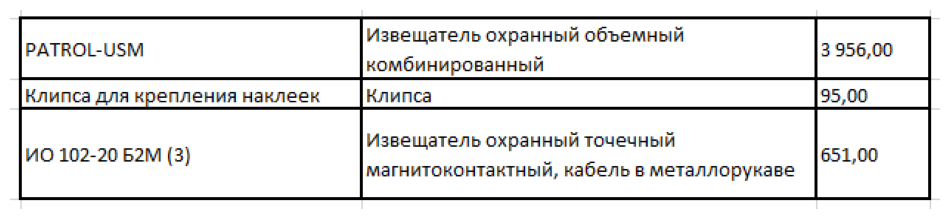

Изображение с обнаруженной таблицей:


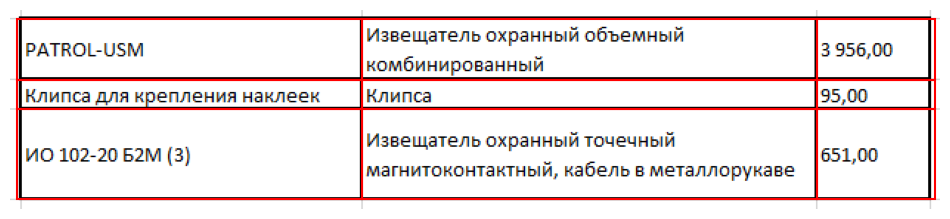

Распознанная таблица сохранена в ./results_1/table_1_base_contrast_070.xlsx
Затраченное время: 0.505 секунд
Всего ошибок: 66
Точность распознавания: 0.629


,0,1,2
0,PATROL-USM,охранный объемный,"3 956,00"
1,[Клипса для крепления наклеек,None,"195,00,"
2,M0 102-20 52M (3),охранный точечный\nкабель в металлорукаве,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_160.png


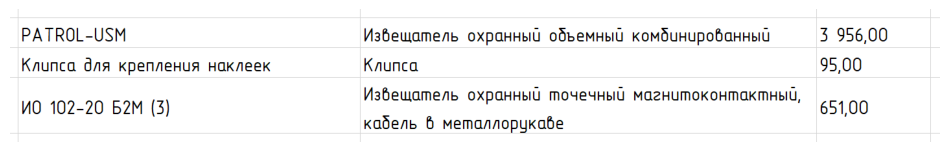

Изображение с обнаруженной таблицей:


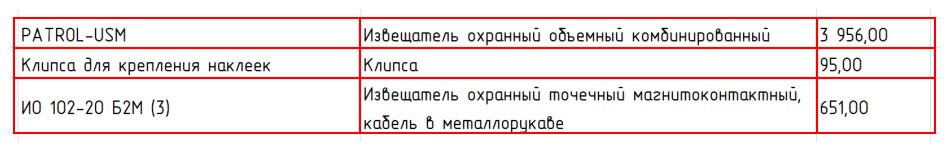

Распознанная таблица сохранена в ./results_1/table_1_gost_160.xlsx
Затраченное время: 0.498 секунд
Всего ошибок: 28
Точность распознавания: 0.843


,0,1,2
0,PATROL-USM,охранный объемный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 метоллорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_130.png


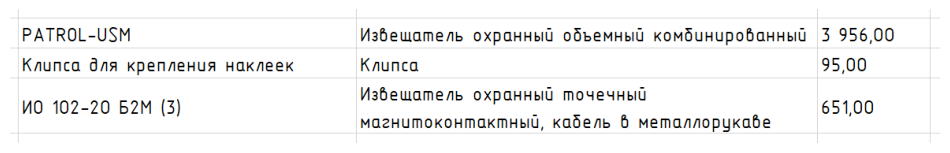

Изображение с обнаруженной таблицей:


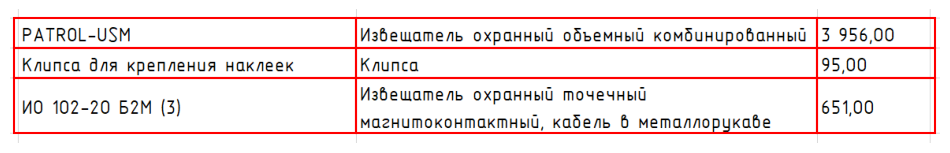

Распознанная таблица сохранена в ./results_1/table_1_gost_130.xlsx
Затраченное время: 0.525 секунд
Всего ошибок: 24
Точность распознавания: 0.865


,0,1,2
0,PATROL-USM,охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6 метоллорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_100.png


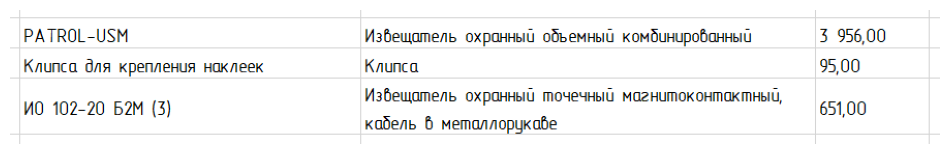

Изображение с обнаруженной таблицей:


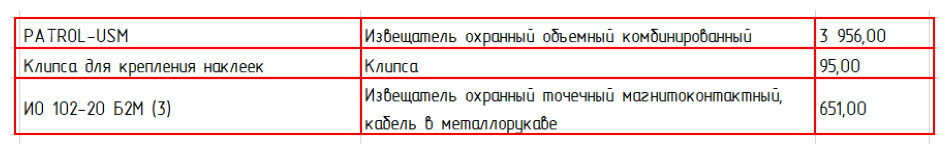

Распознанная таблица сохранена в ./results_1/table_1_gost_100.xlsx
Затраченное время: 0.450 секунд
Всего ошибок: 43
Точность распознавания: 0.758


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),Избещатель охранный точечный\nкабель 6,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_070.png


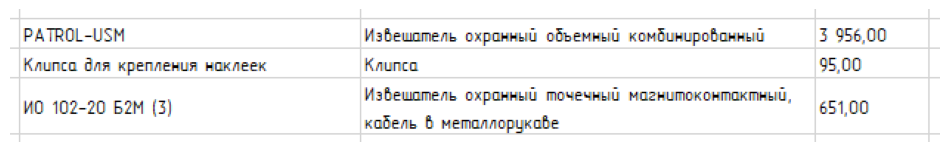

Изображение с обнаруженной таблицей:


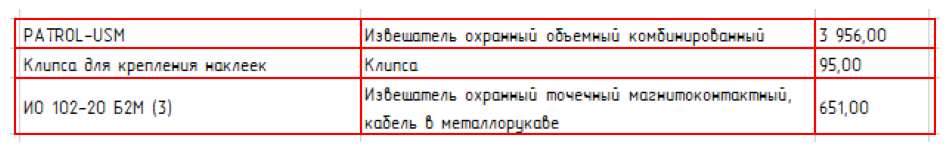

Распознанная таблица сохранена в ./results_1/table_1_gost_070.xlsx
Затраченное время: 0.515 секунд
Всего ошибок: 52
Точность распознавания: 0.708


,0,1,2
0,PATROL-USM,Извешалель охранный объенный комбинированный,"3 956,00"
1,Knunca для крепления наклеек,None,"95,00"
2,ИО 102-20 52M (3),Извешалель охранный почечный\nкобель 6 memannopyxabe,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_160.png


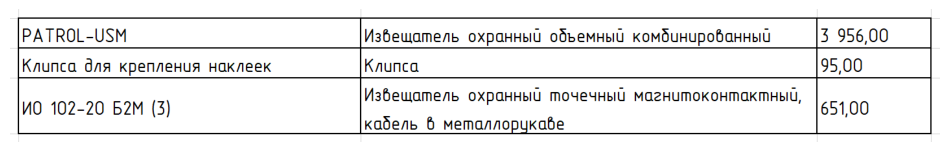

Изображение с обнаруженной таблицей:


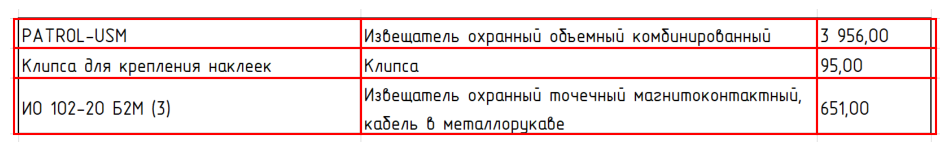

Распознанная таблица сохранена в ./results_1/table_1_gost_contrast_160.xlsx
Затраченное время: 0.490 секунд
Всего ошибок: 46
Точность распознавания: 0.742


,0,1,2
0,PATROL-USM,охранный объемный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 Memannopykabe","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_130.png


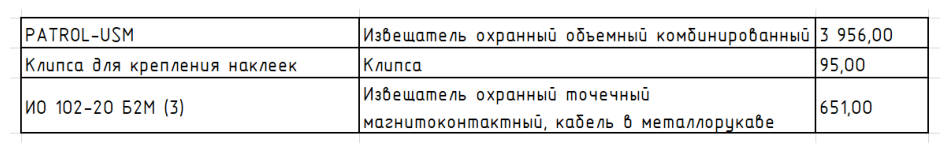

Изображение с обнаруженной таблицей:


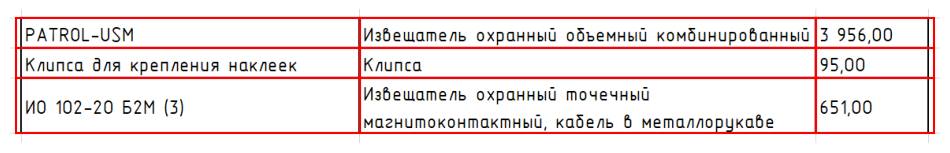

Распознанная таблица сохранена в ./results_1/table_1_gost_contrast_130.xlsx
Затраченное время: 0.501 секунд
Всего ошибок: 53
Точность распознавания: 0.702


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|5 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,MO 102-20 Б2М (3),охранный точечный\nкабель 6 Memannopykabe,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_100.png


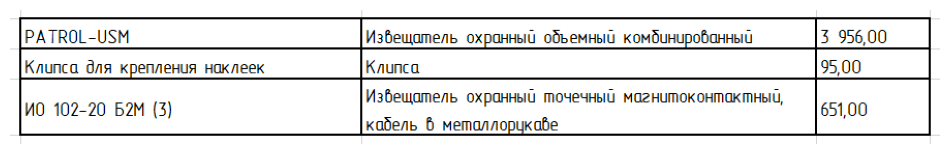

Изображение с обнаруженной таблицей:


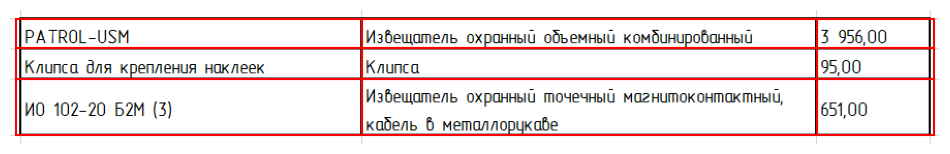

Распознанная таблица сохранена в ./results_1/table_1_gost_contrast_100.xlsx
Затраченное время: 0.418 секунд
Всего ошибок: 39
Точность распознавания: 0.781


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00"
1,для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),Избещатель охранный почечный\nкабель 6 метоллорцкаве,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_070.png


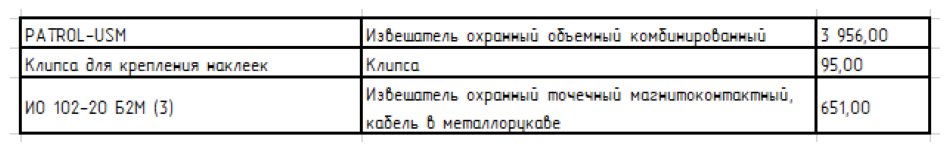

Изображение с обнаруженной таблицей:


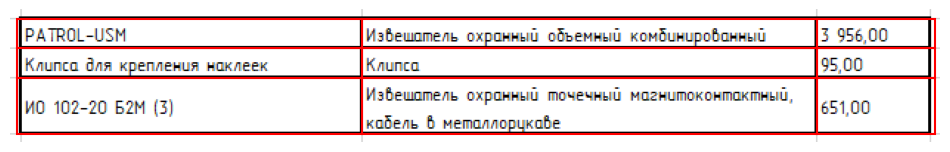

Распознанная таблица сохранена в ./results_1/table_1_gost_contrast_070.xlsx
Затраченное время: 0.465 секунд
Всего ошибок: 69
Точность распознавания: 0.612


,0,1,2
0,PATROL-USM,[Извешалель охранный объемный комбинированный,"5 956,00"
1,для крепления наклеек,Knunca,None
2,IMO 102-20 2M (3),Извешалель охранный почечный\n6,5100



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_160.png


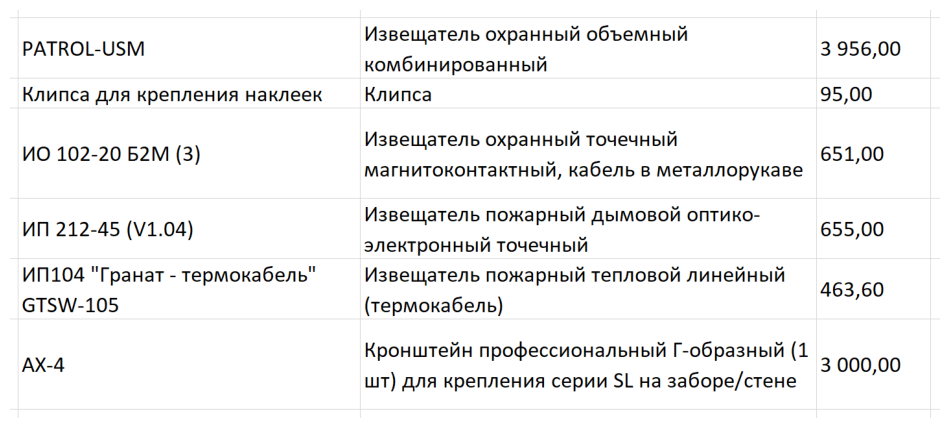

Изображение с обнаруженной таблицей:


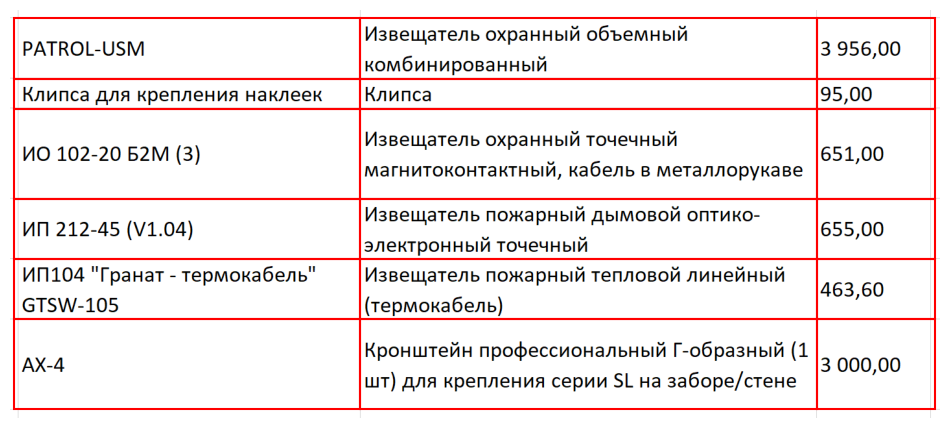

Распознанная таблица сохранена в ./results_1/table_2_base_160.xlsx
Затраченное время: 0.802 секунд
Всего ошибок: 3
Точность распознавания: 0.993


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1\nшт) для крепления серии SL на заборе/стене,"000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_130.png


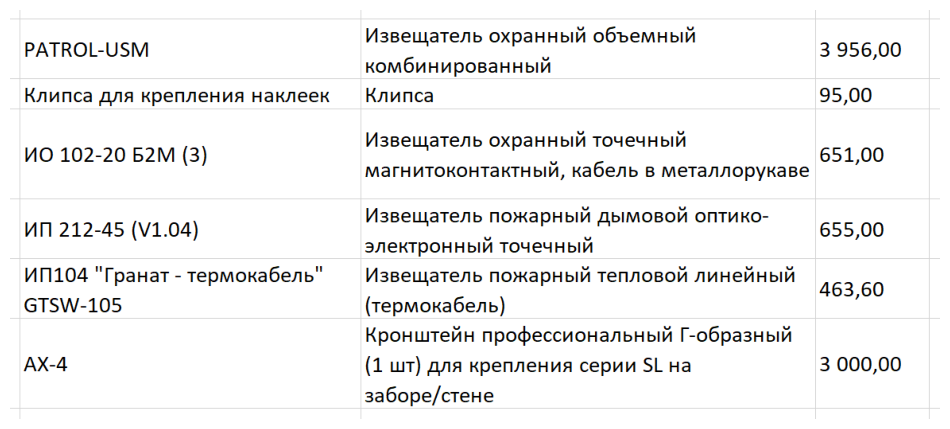

Изображение с обнаруженной таблицей:


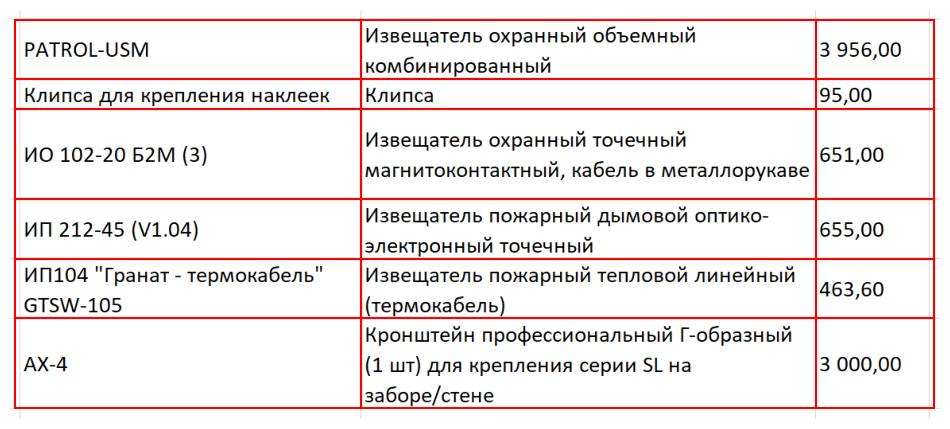

Распознанная таблица сохранена в ./results_1/table_2_base_130.xlsx
Затраченное время: 0.859 секунд
Всего ошибок: 3
Точность распознавания: 0.993


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","51,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_100.png


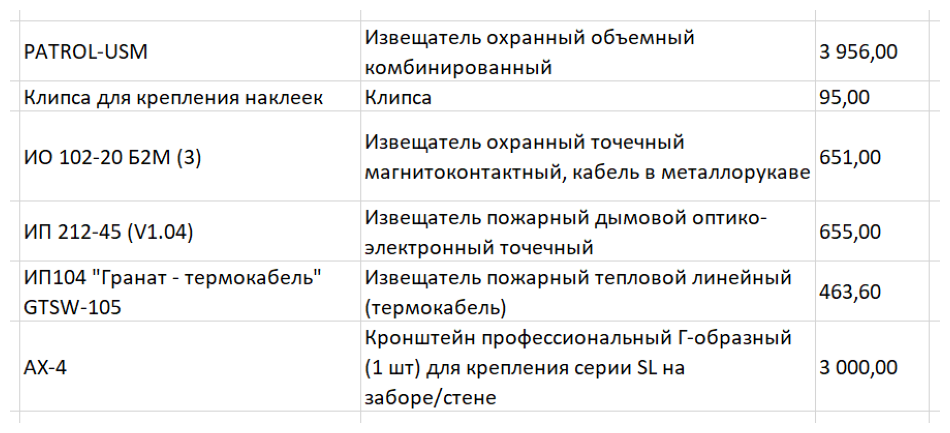

Изображение с обнаруженной таблицей:


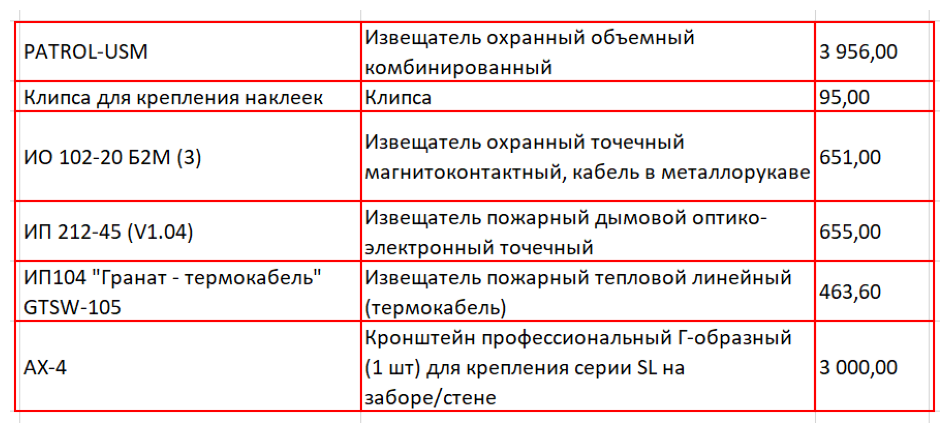

Распознанная таблица сохранена в ./results_1/table_2_base_100.xlsx
Затраченное время: 0.692 секунд
Всего ошибок: 3
Точность распознавания: 0.993


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",",00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,AX-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_070.png


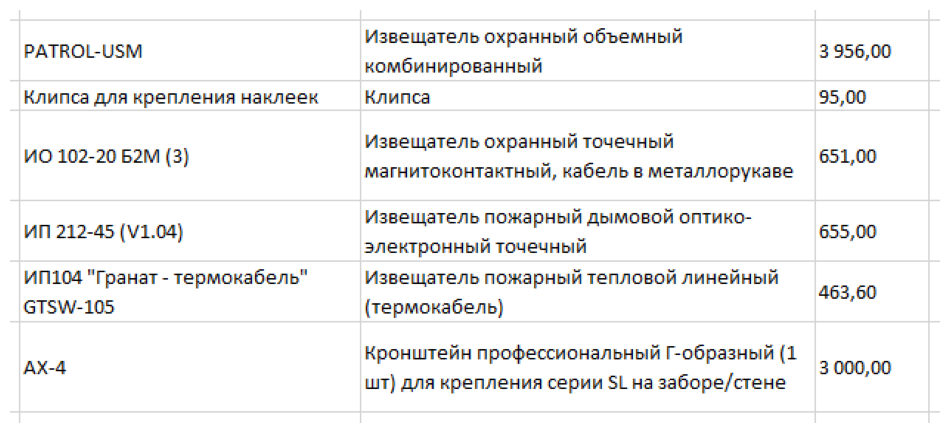

Изображение с обнаруженной таблицей:


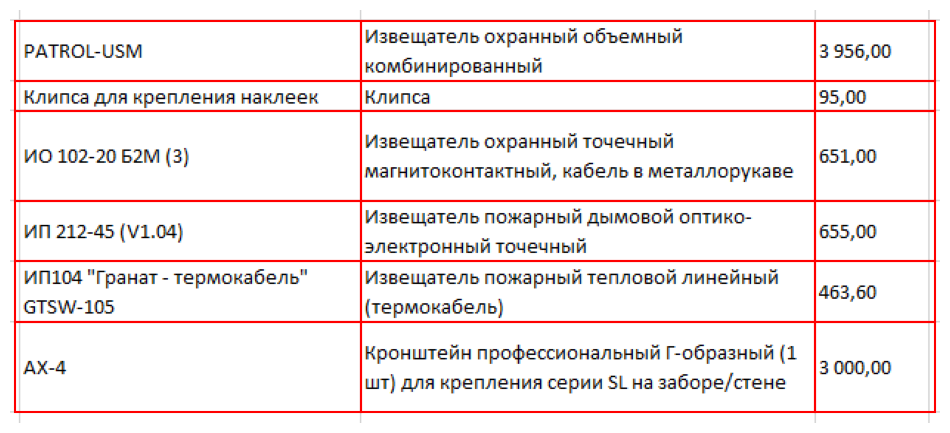

Распознанная таблица сохранена в ./results_1/table_2_base_070.xlsx
Затраченное время: 0.582 секунд
Всего ошибок: 39
Точность распознавания: 0.907


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"35,00"
2,ИО 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"""Гранат - термокабель""",извещатель пожарный тепловой линейный,"463,60"
5,None,Кронштейн профессиональный Г-образный (1\nшт) для крепления серии на заборе/стене,"3000,00."



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_160.png


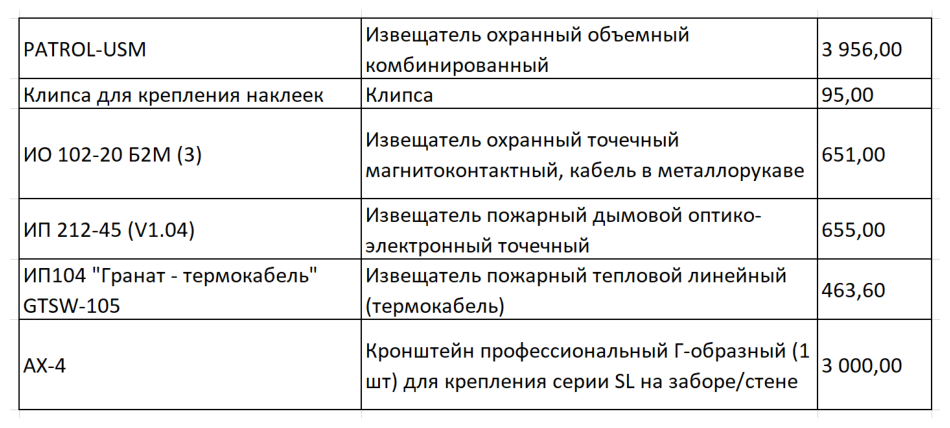

Изображение с обнаруженной таблицей:


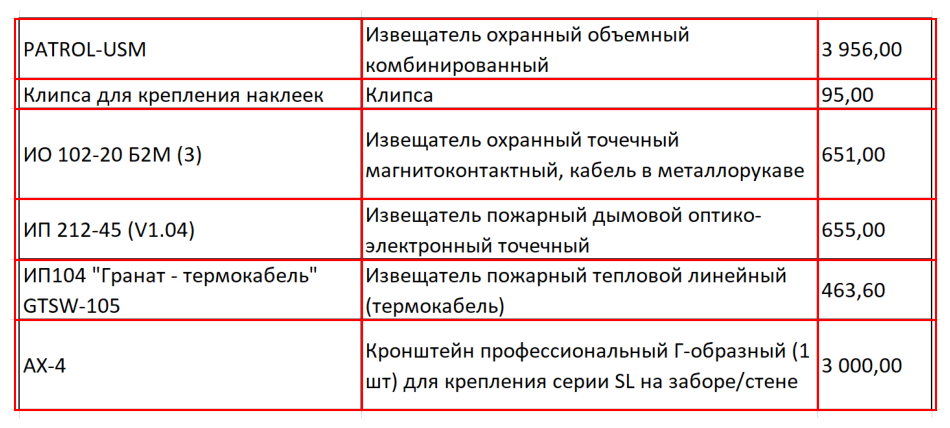

Распознанная таблица сохранена в ./results_1/table_2_base_contrast_160.xlsx
Затраченное время: 0.821 секунд
Всего ошибок: 3
Точность распознавания: 0.993


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","51,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1\nшт) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_130.png


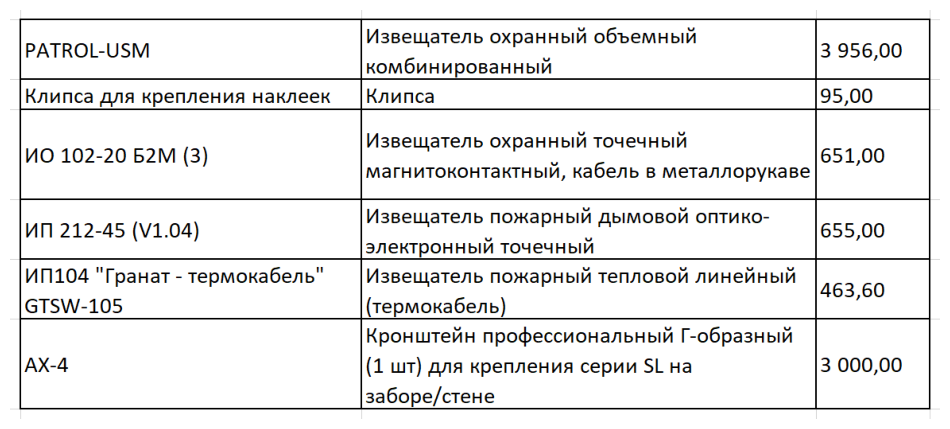

Изображение с обнаруженной таблицей:


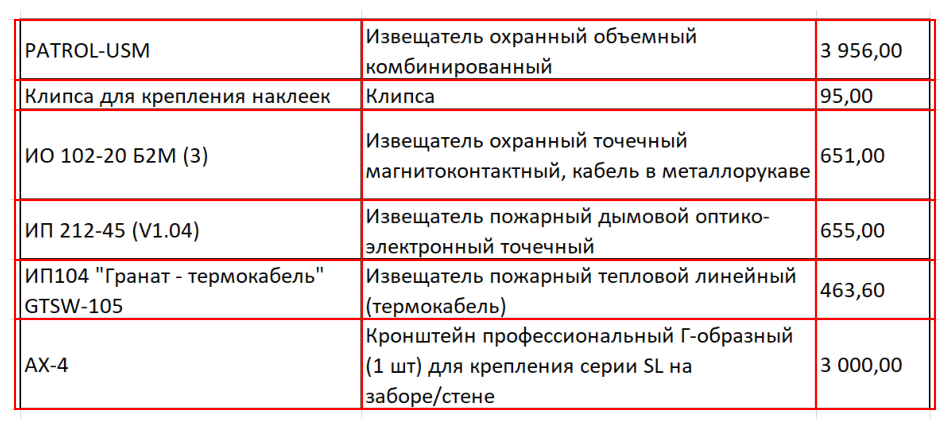

Распознанная таблица сохранена в ./results_1/table_2_base_contrast_130.xlsx
Затраченное время: 0.930 секунд
Всего ошибок: 8
Точность распознавания: 0.981


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_100.png


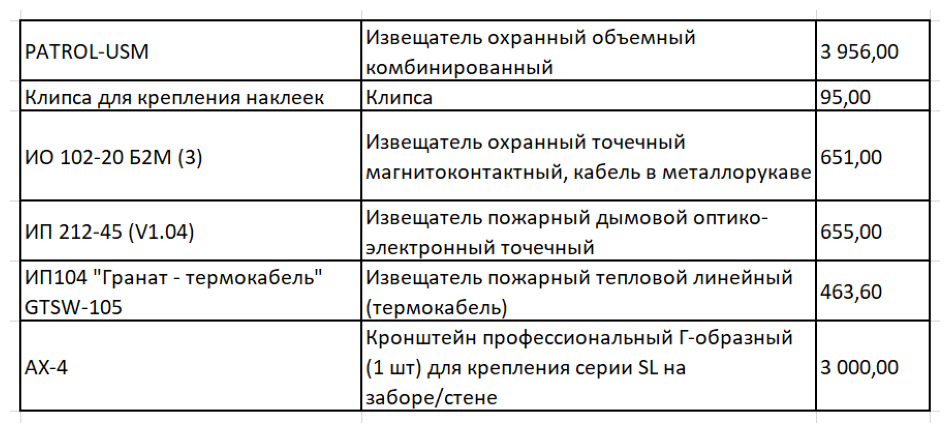

Изображение с обнаруженной таблицей:


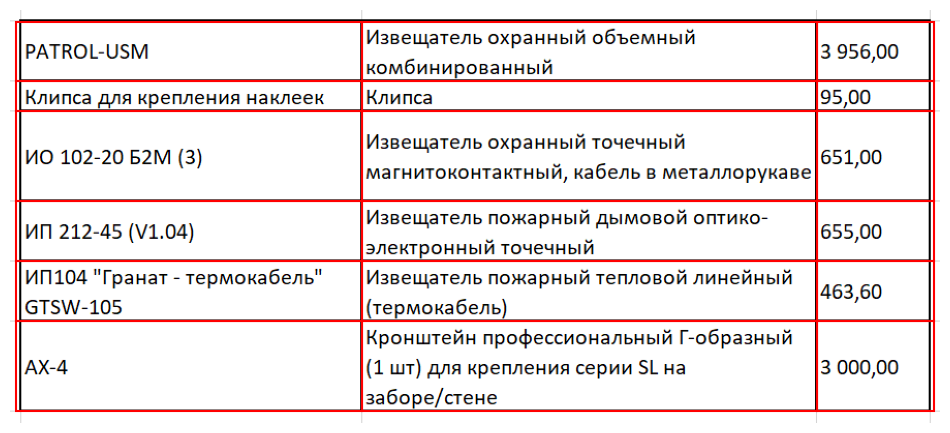

Распознанная таблица сохранена в ./results_1/table_2_base_contrast_100.xlsx
Затраченное время: 0.712 секунд
Всего ошибок: 6
Точность распознавания: 0.986


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",‚00
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_070.png


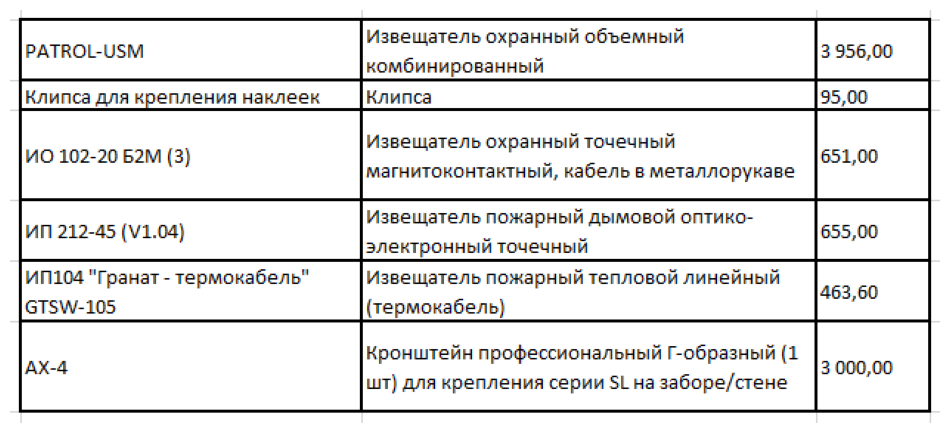

Изображение с обнаруженной таблицей:


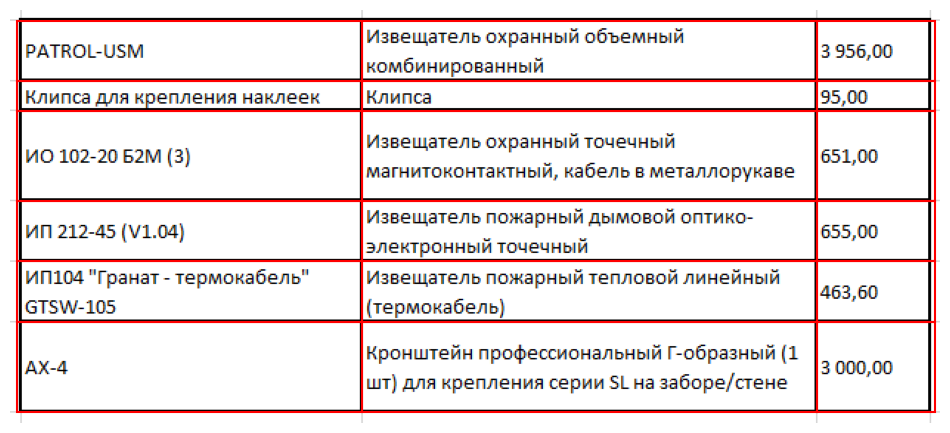

Распознанная таблица сохранена в ./results_1/table_2_base_contrast_070.xlsx
Затраченное время: 0.979 секунд
Всего ошибок: 106
Точность распознавания: 0.748


,0,1,2
0,PATROL-USM,охранный объемный\nкомбинированный,"3 956,00"
1,[Клипса для крепления наклеек,None,"195,00,"
2,A 102-20 62M (3),охранный точечный\nкабель в металлорукаве,"651,00"
3,212-45 (У1.04),Извещатель пожарный дымовой оптико-\nточечный,"655,00"
4,"""Гранат - термокабель""",пожарный тепловой линейный\n(repmoxaGens),"[463,60"
5,None,Кронштейн профессиональный Г-образный (1\nlu) для крепления серии SL на заборе/стене,"3000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_160.png


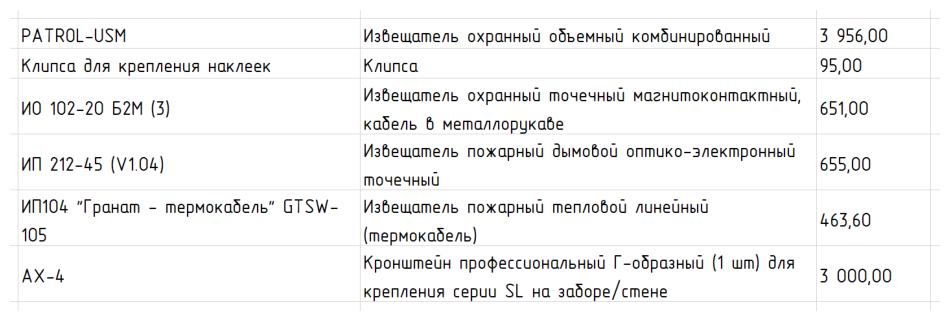

Изображение с обнаруженной таблицей:


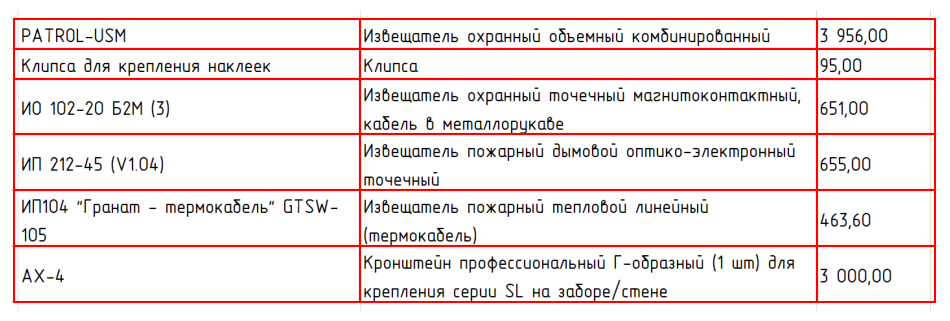

Распознанная таблица сохранена в ./results_1/table_2_gost_160.xlsx
Затраченное время: 0.962 секунд
Всего ошибок: 85
Точность распознавания: 0.798


,0,1,2
0,PATROL-USM,Извещатель охранный объемный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 метоллорукаве","651,00"
3,ИП 212-45 (V1.04),пожарный дымовой оптико-электронный\nточечный,"655,00"
4,"""Гранат - GTSW-\n105",пожарный линецный,"463,60"
5,AX-4,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_130.png


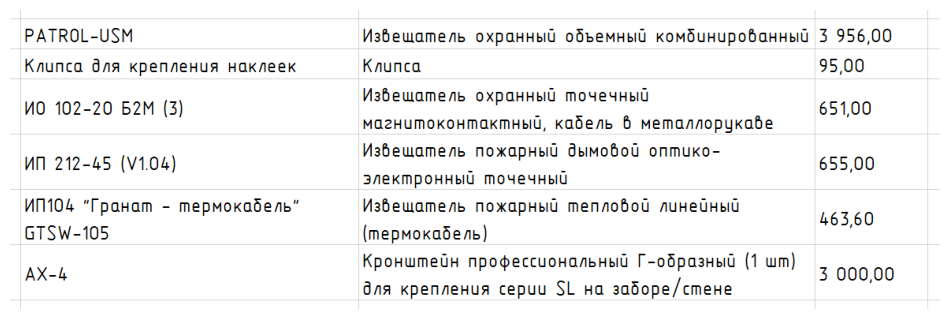

Изображение с обнаруженной таблицей:


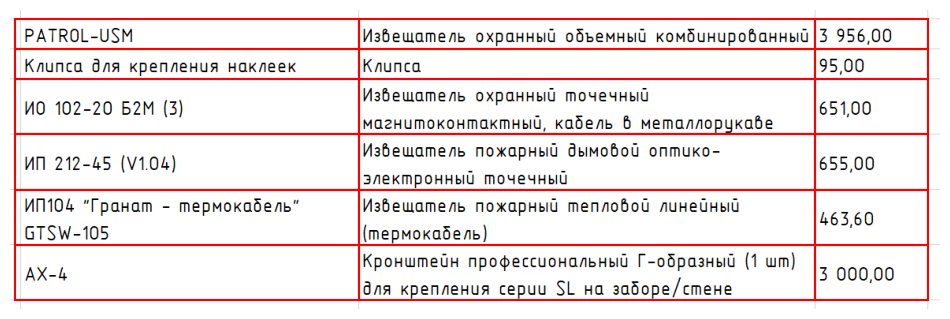

Распознанная таблица сохранена в ./results_1/table_2_gost_130.xlsx
Затраченное время: 0.882 секунд
Всего ошибок: 88
Точность распознавания: 0.790


,0,1,2
0,PATROL-USM,охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6 mMemannopyKabe","651,00"
3,ИП 212-45 (V1.04),пожарный дымовой оптико-\nэлектронный точечный,"655,00"
4,ИП1О4 “Гранат - термокабель”\nGTSW-105,пожарный тепловой линейный\n(пермокабель),"463,60"
5,AX-4,профессиональный Г-образный (1 wm)\nдля крепления cepuu SL на sadope/cmene,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_100.png


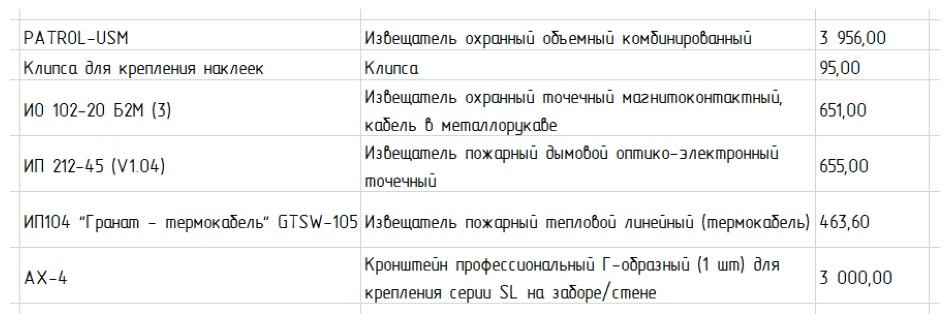

Изображение с обнаруженной таблицей:


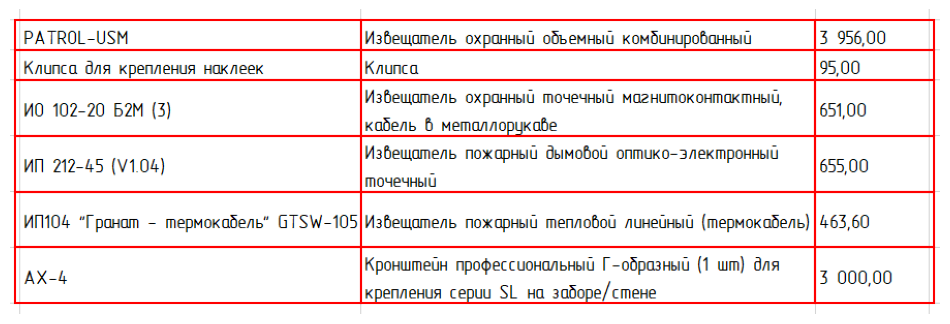

Распознанная таблица сохранена в ./results_1/table_2_gost_100.xlsx
Затраченное время: 0.770 секунд
Всего ошибок: 100
Точность распознавания: 0.762


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),Избещатель охранный точечный\nкабель 6 Memannopykabe,"651,00"
3,ИП 212-45 (V1.04),Избещатель пожарный\nпочечный,"655,00"
4,“Гранат - GTSW-105,Извещатель пожарный тепловой (термокабель),"463,60"
5,АХ-&,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_070.png


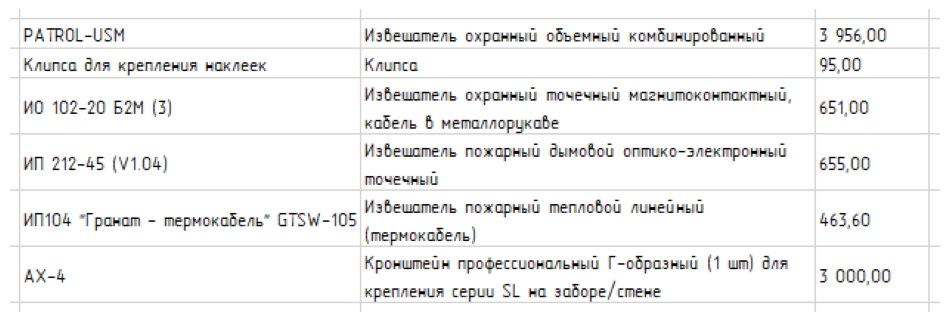

Изображение с обнаруженной таблицей:


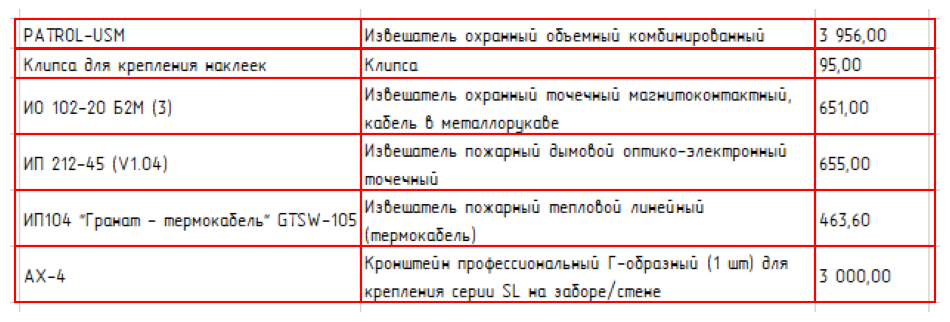

Распознанная таблица сохранена в ./results_1/table_2_gost_070.xlsx
Затраченное время: 0.649 секунд
Всего ошибок: 160
Точность распознавания: 0.619


,0,1,2
0,PATROL-USM,Извешалель охранный объенный комбинированный,"3 956,00"
1,Knunca для крепления наклеек,None,"95,00"
2,ИО 102-20 52M (3),Извешалель охранный почечный\nкобель 6 memannopyxabe,"651,00"
3,ИП 212-45,Извешалель дымовой\nпочечный,655.00
4,- GTSW-105,Извешалель пожарный mennotod линейный,"463,60"
5,None,Кронштейн профессиональный Г-образный (1 um) для\nкрепления SL a,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_160.png


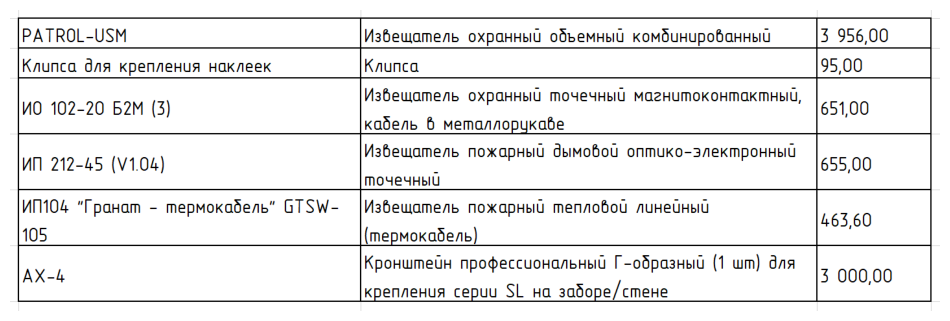

Изображение с обнаруженной таблицей:


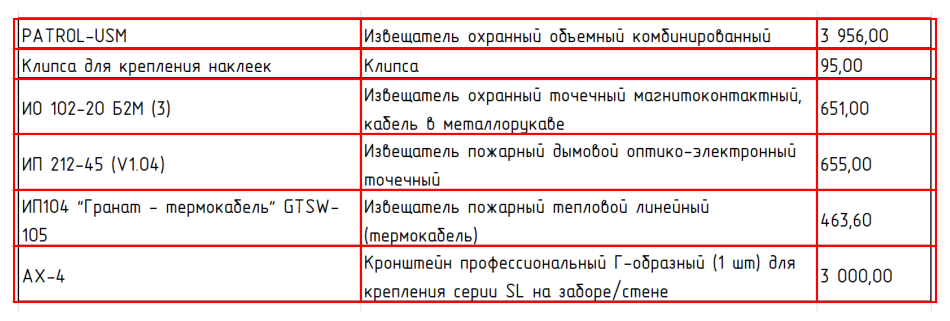

Распознанная таблица сохранена в ./results_1/table_2_gost_contrast_160.xlsx
Затраченное время: 0.943 секунд
Всего ошибок: 123
Точность распознавания: 0.707


,0,1,2
0,PATROL-USM,охранный объемный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 Memannopykabe","651,00"
3,ИП 212-45 (V1.04),пожарный дымовой\nточечный,"655,00"
4,"""Гранат - GTSW-\n105",пожарный линецный\n(mepmokadenb),"463,60"
5,AX-4,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_130.png


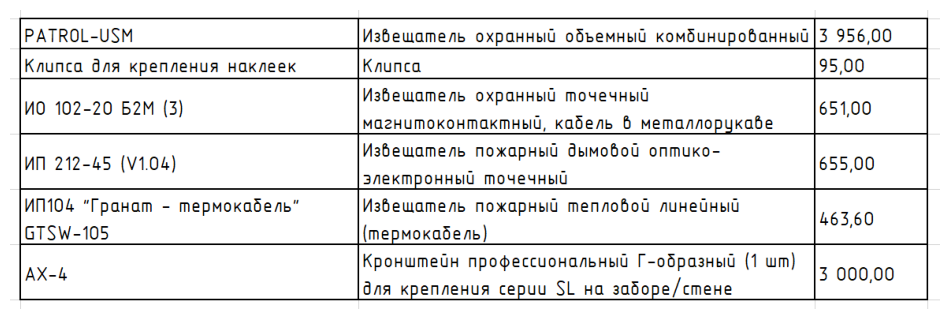

Изображение с обнаруженной таблицей:


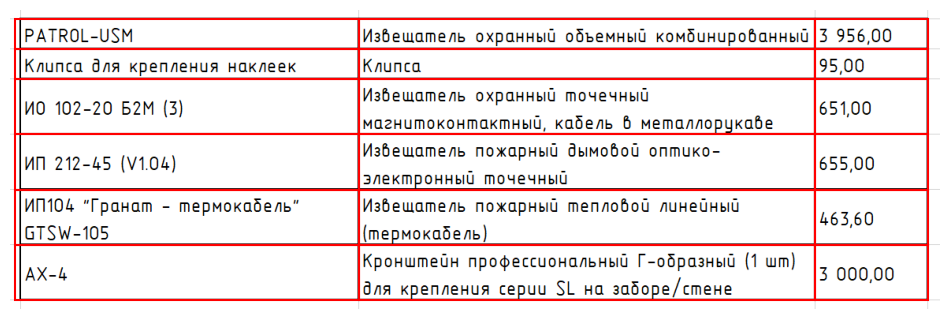

Распознанная таблица сохранена в ./results_1/table_2_gost_contrast_130.xlsx
Затраченное время: 0.990 секунд
Всего ошибок: 94
Точность распознавания: 0.776


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|5 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,MO 102-20 Б2М (3),охранный точечный\nкабель 6 Memannopykabe,"651,00"
3,ИП 212-45 (V1.04),пожарный оптико-\nэлектронный точечный,"655,00"
4,"""Гранат - термокабель”\nGTSW-105",пожарный тепловой линейный\n(пермокабель),"463,60"
5,AX-4,Кронштейн профессиональный Г-образный (1 wm)\nдля крепления cepuu SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_100.png


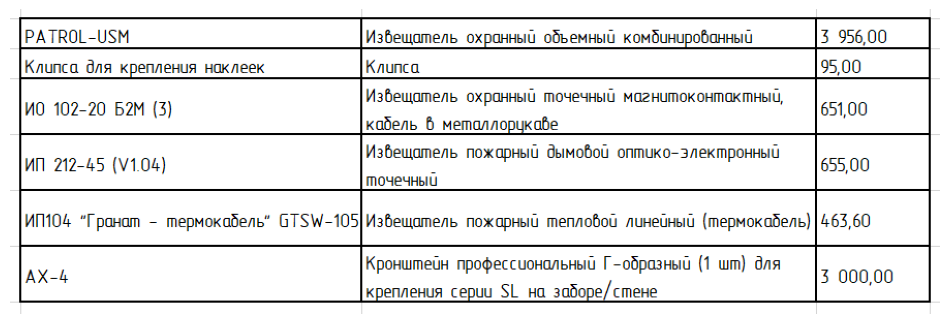

Изображение с обнаруженной таблицей:


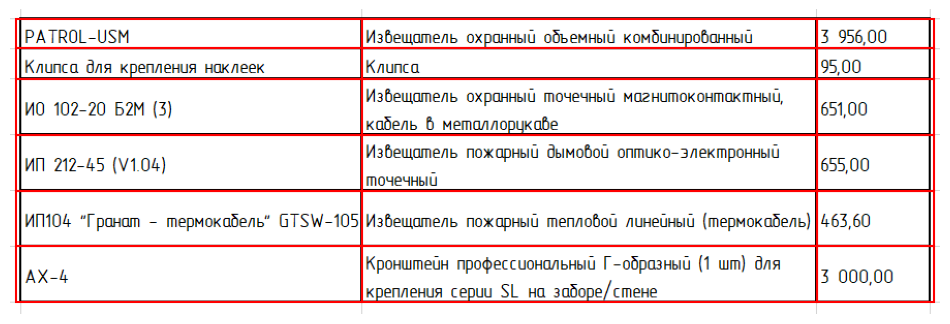

Распознанная таблица сохранена в ./results_1/table_2_gost_contrast_100.xlsx
Затраченное время: 0.770 секунд
Всего ошибок: 94
Точность распознавания: 0.776


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00"
1,для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),Избещатель охранный точечный\nкабель 6 метоллорцкаве,"651,00"
3,ИП 212-45 (V1.04),Избещатель пожарный дымовой оптико-злектронный\nточечный,"655,00"
4,“Гранат - пермокобель“,пожарный пеплобоб линебный (пермокобель,"[463,60"
5,АХ-&,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии 51 на,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_070.png


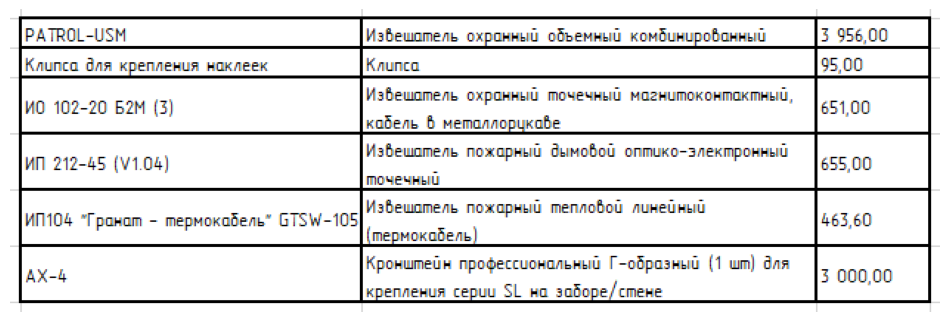

Изображение с обнаруженной таблицей:


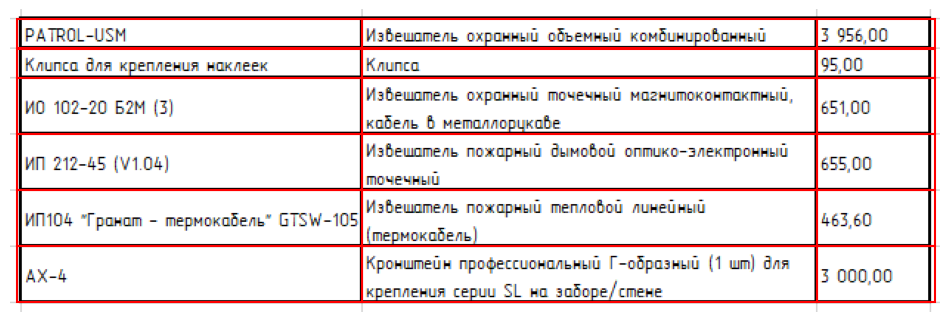

Распознанная таблица сохранена в ./results_1/table_2_gost_contrast_070.xlsx
Затраченное время: 0.648 секунд
Всего ошибок: 200
Точность распознавания: 0.524


,0,1,2
0,PATROL-USM,[Извешалель охранный объемный комбинированный,"5 956,00"
1,для крепления наклеек,Knunca,None
2,IMO 102-20 2M (3),Извешалель охранный почечный\n6,5100
3,Мп 212-45 (v1.04),Извешалель дымовой\nпочечный,55.00
4,- GTSW-105|,пожарный mennotod линейный,"463,60"
5,None,профессиональный Г-образный (1 wn) для\ncepuu SL мо,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_160.png


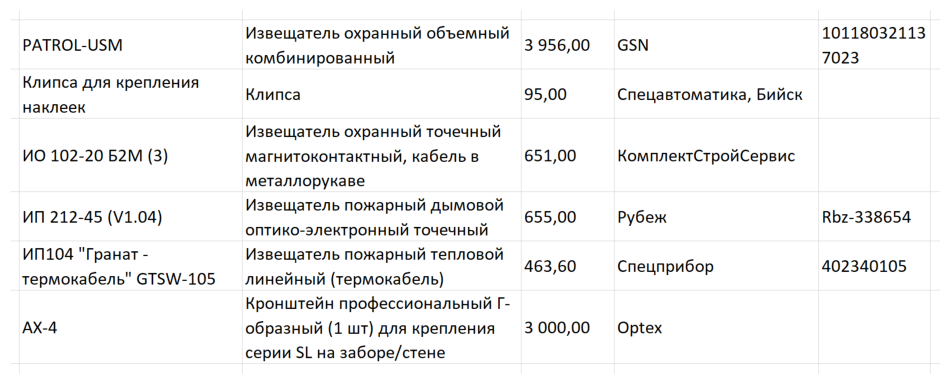

Изображение с обнаруженной таблицей:


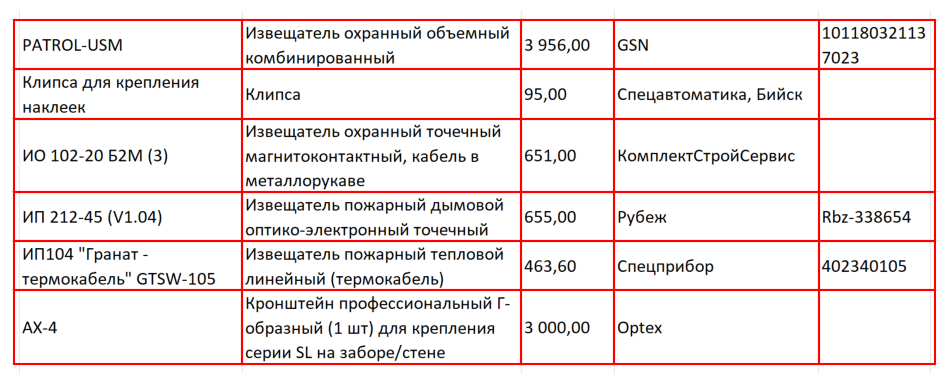

Распознанная таблица сохранена в ./results_1/table_3_base_160.xlsx
Затраченное время: 1.090 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,10118032113\n7023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_130.png


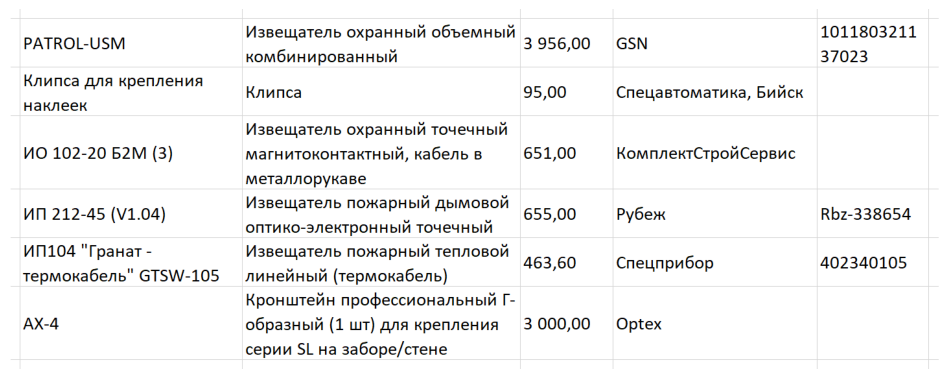

Изображение с обнаруженной таблицей:


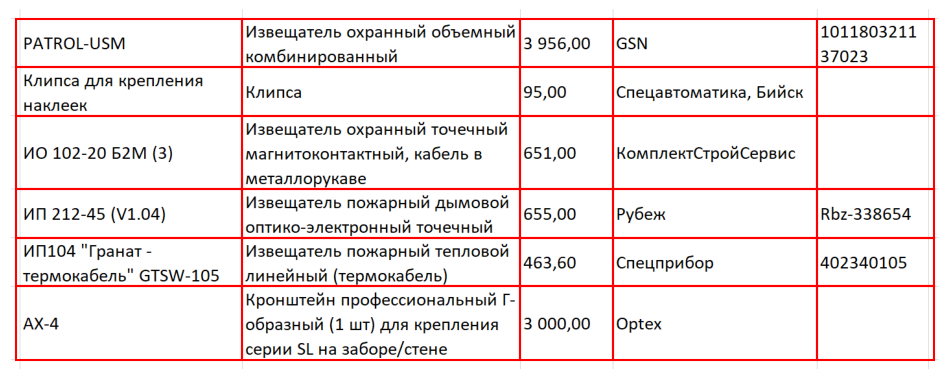

Распознанная таблица сохранена в ./results_1/table_3_base_130.xlsx
Затраченное время: 1.162 секунд
Всего ошибок: 4
Точность распознавания: 0.992


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,1011803211\n37023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 52M (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_100.png


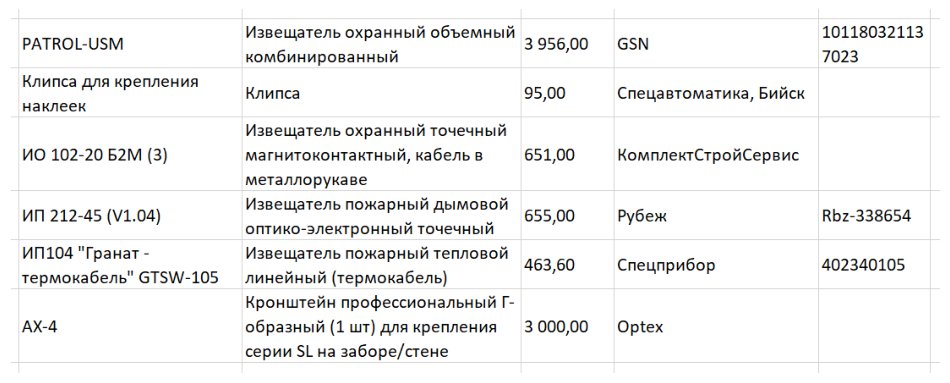

Изображение с обнаруженной таблицей:


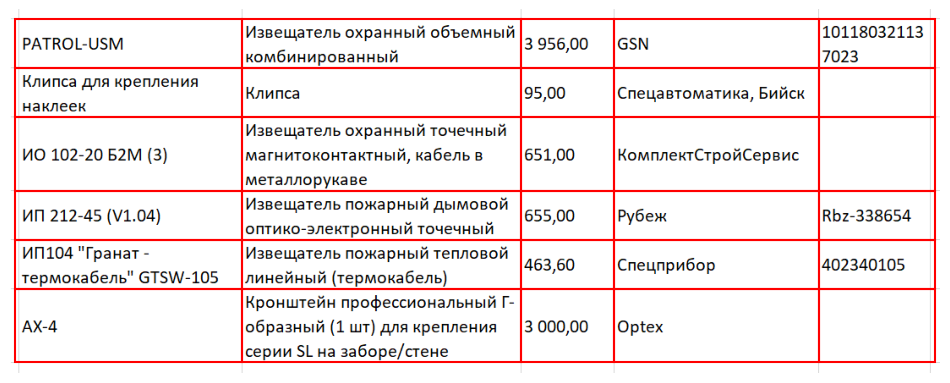

Распознанная таблица сохранена в ./results_1/table_3_base_100.xlsx
Затраченное время: 0.805 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00",GSN,10118032113\n7023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,AX-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_070.png


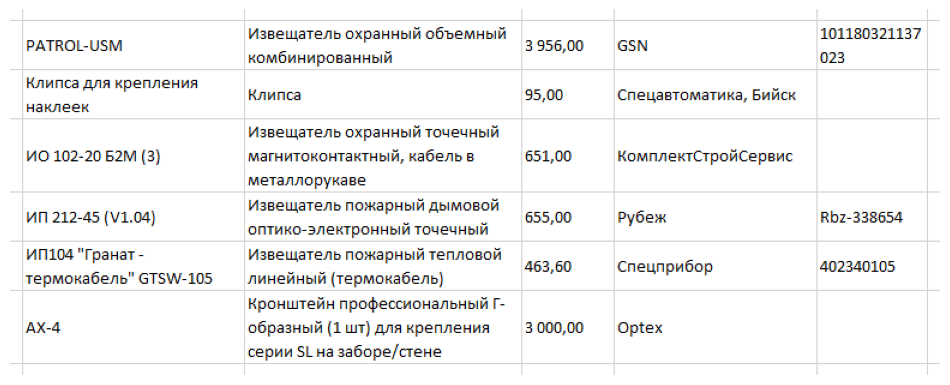

Изображение с обнаруженной таблицей:


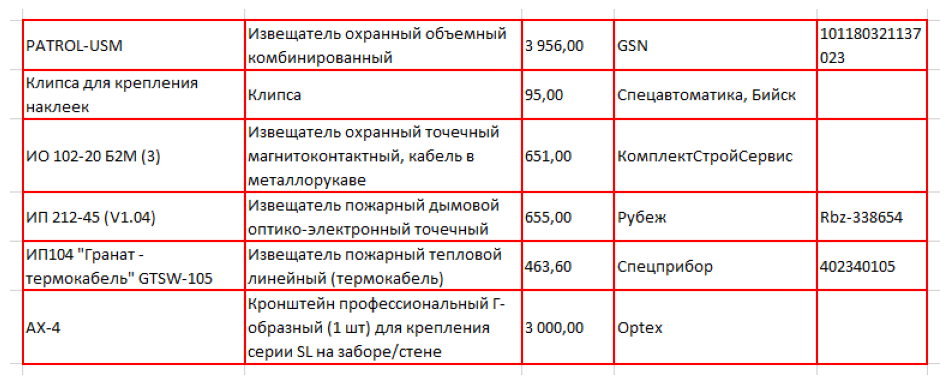

Распознанная таблица сохранена в ./results_1/table_3_base_070.xlsx
Затраченное время: 0.732 секунд
Всего ошибок: 52
Точность распознавания: 0.899


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00",GSN,101180321137\n023
1,Клипса для крепления\nнаклеек,Клипса,"35,00","Спецавтоматика, Бийск.",None
2,MMO 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный,\nметаллорукаве","651,00",Комплектстройсервис,None
3,ИП 212-45 (V1.04),извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",рубеж,Rbz-338654
4,"""Гранат -\nтермокабель"" GTSW-105",извещатель пожарный тепловой\nлинейный,"463,60",None,402340105
5,None,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_160.png


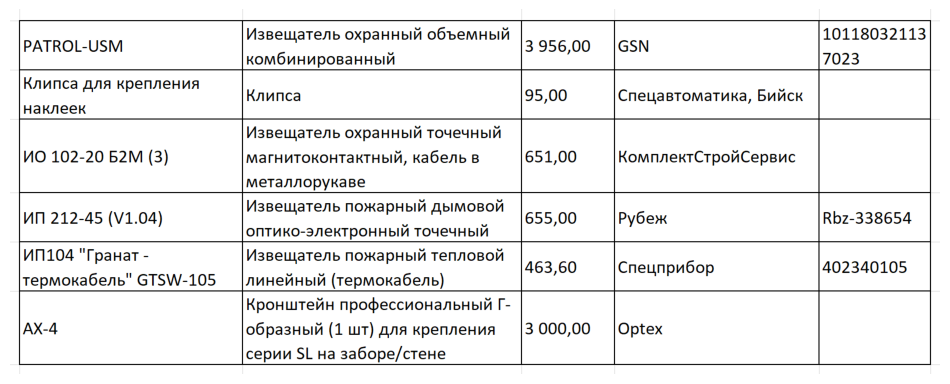

Изображение с обнаруженной таблицей:


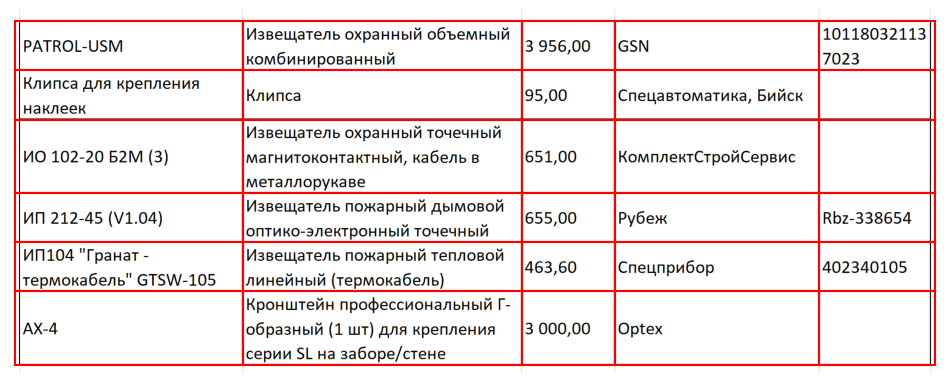

Распознанная таблица сохранена в ./results_1/table_3_base_contrast_160.xlsx
Затраченное время: 1.177 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,10118032113\n7023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактн ый, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_130.png


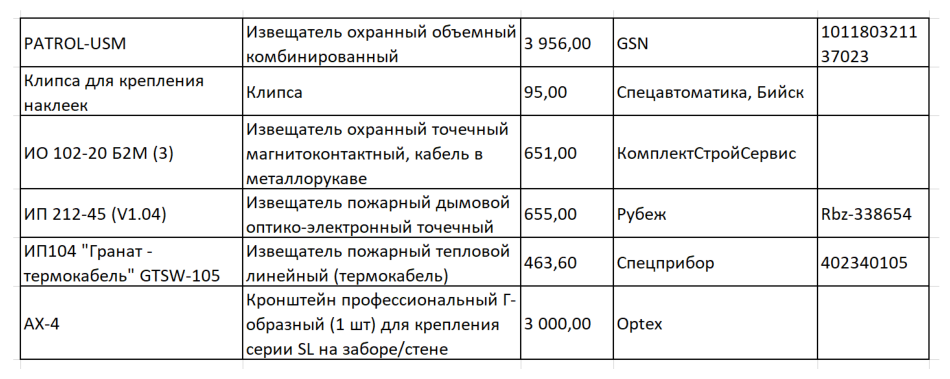

Изображение с обнаруженной таблицей:


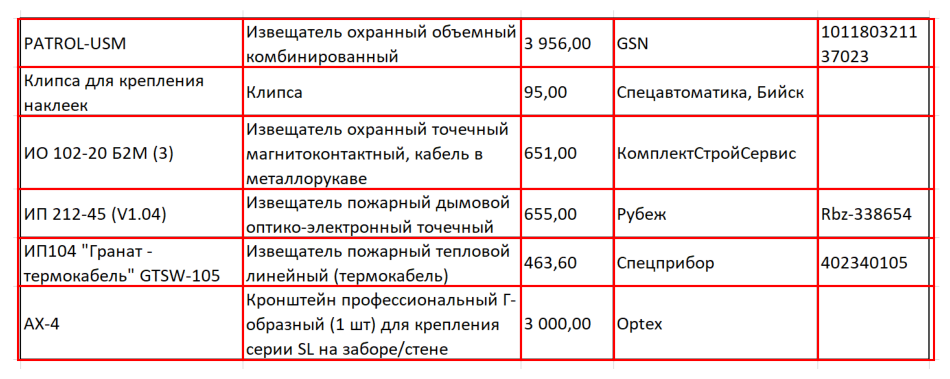

Распознанная таблица сохранена в ./results_1/table_3_base_contrast_130.xlsx
Затраченное время: 1.079 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,1011803211\n37023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_100.png


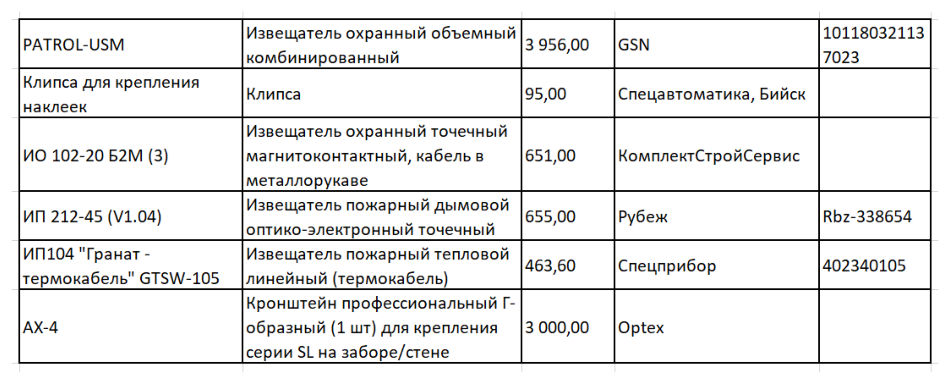

Изображение с обнаруженной таблицей:


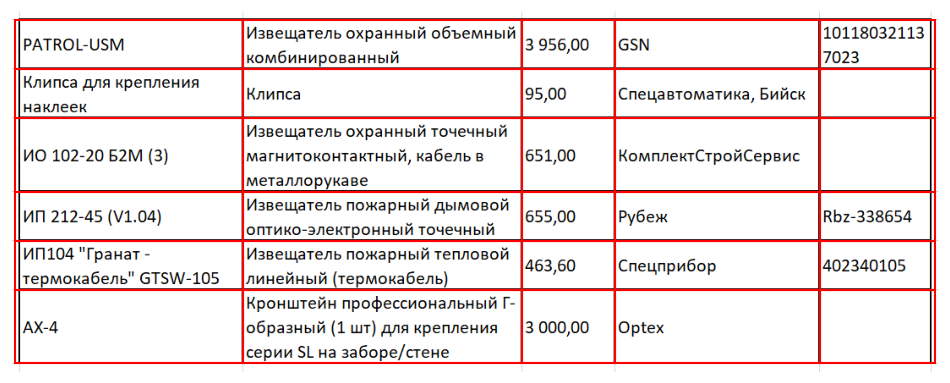

Распознанная таблица сохранена в ./results_1/table_3_base_contrast_100.xlsx
Затраченное время: 0.899 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00",GSN,10118032113\n7023
1,Клипса для крепления\nнаклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в\nметаллорукаве","651,00",КомплектСтройСервис,None
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат -\nтермокабель"" GTSW-105",Извещатель пожарный тепловой\nлинейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nсерии SL на заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_070.png


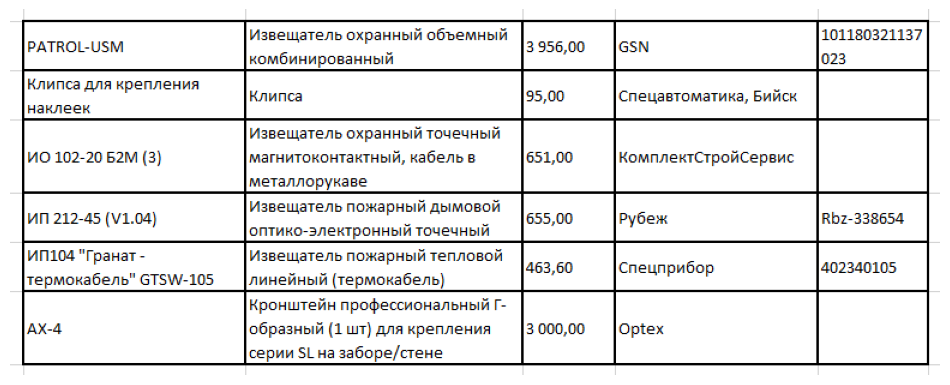

Изображение с обнаруженной таблицей:


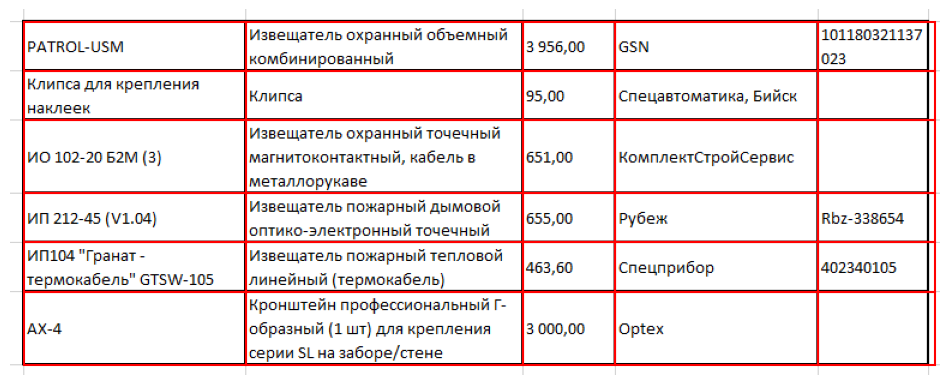

Распознанная таблица сохранена в ./results_1/table_3_base_contrast_070.xlsx
Затраченное время: 0.891 секунд
Всего ошибок: 211
Точность распознавания: 0.591


,0,1,2,3,4
0,PATROL-USM,охранный объемный,"3 956,00",None,[101180321137
1,для крепления,None,"195,00",Бийск,None
2,M0 102-20 52M (3),охранный точечный\nкабельв,"651,00",Комплектстройсервис,None
3,An 212-45 (V1.04),пожарный дымовой\nточечный,"655,00",Рубеж,Rb2-338654
4,"""Гранат -\nGTSW-105",пожарный тепловой\n[линейный,None,Спецприбор,None
5,None,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\nSL на заборе/стене,"3000,00.",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_160.png


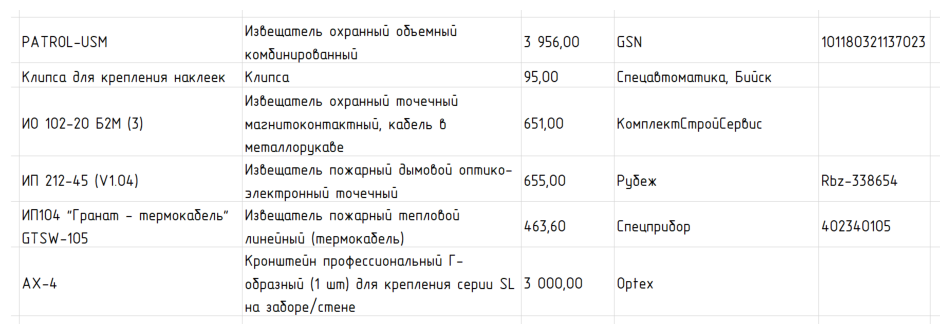

Изображение с обнаруженной таблицей:


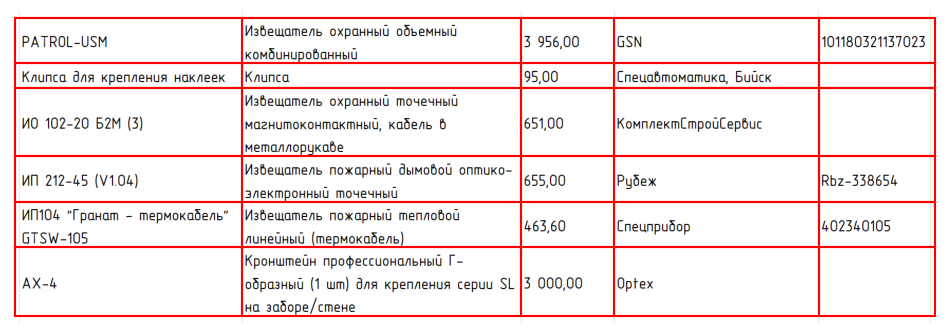

Распознанная таблица сохранена в ./results_1/table_3_gost_160.xlsx
Затраченное время: 1.172 секунд
Всего ошибок: 136
Точность распознавания: 0.736


,0,1,2,3,4
0,PATROL-USM,охранный объемный\nкомбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00",Бийск,None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кобель 6\nMemannopykabe","651,00",None,None
3,ИП 212-45 (V1.04),Vsbewamenb пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
4,"""Гранат - термокабель”\nGTSW-105",пожарный\nлинейный,"463,60",Cneunpudop,402340105
5,AX-4,профессиональный Г-\nобразный (1 шт) для крепления cepuu SL\nна заборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_130.png


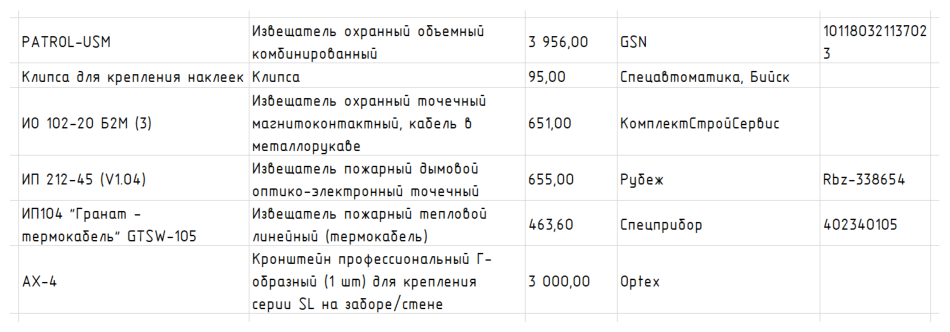

Изображение с обнаруженной таблицей:


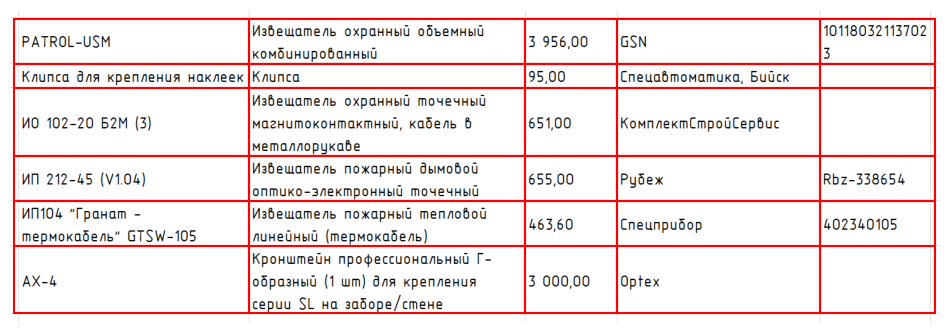

Распознанная таблица сохранена в ./results_1/table_3_gost_130.xlsx
Затраченное время: 1.222 секунд
Всего ошибок: 113
Точность распознавания: 0.781


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный\nкомбинированный,"3 956,00",GSN,10118032113702\n3
1,Клипса для крепления наклеек,Клипса,"95,00","(пецабтоматика, Бийск",None
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6\nMemannopykabe","651,00",KomnaexmCmpouCepbuc,None
3,ИП 212-45 (V1.04),Избещатель пожарный deimobou\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"""Гранат -\nmepmokadenb” GTSW-105",пожарный тепловой\nлинебный (термокабель),"463,60",None,402340105
5,AX-4,Кронштейн профессиональный Г-\nобразный (1 wm) для крепления\ncepuu SL на sadope/cmene,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_100.png


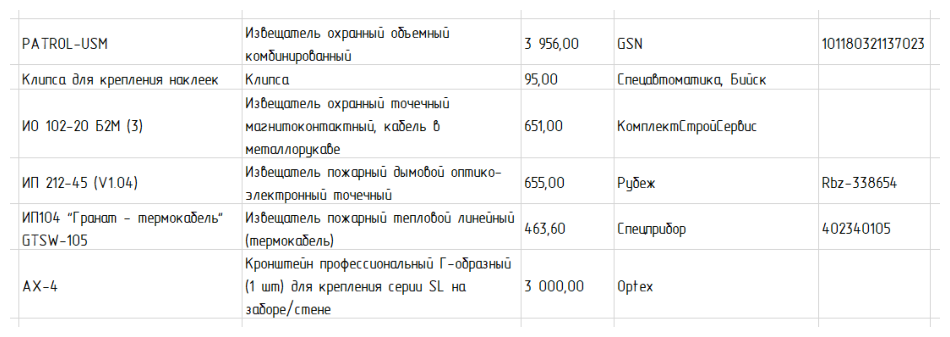

Изображение с обнаруженной таблицей:


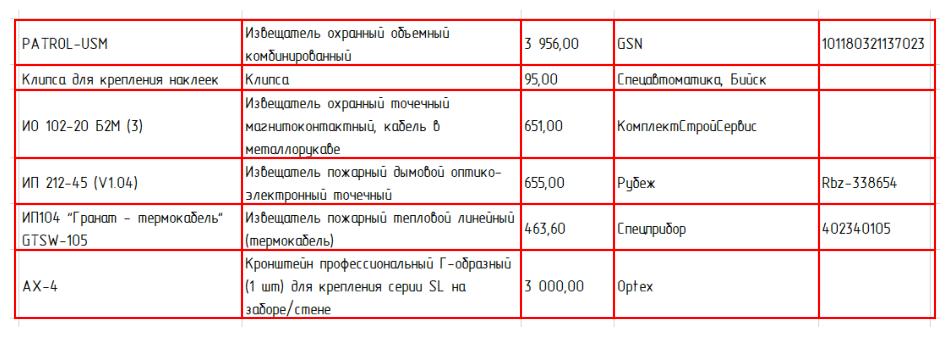

Распознанная таблица сохранена в ./results_1/table_3_gost_100.xlsx
Затраченное время: 0.803 секунд
Всего ошибок: 103
Точность распознавания: 0.800


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный\nкомбинированный,3,GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00",Бибск,None
2,ИО 102-20 52M (3),Избещатель охранный почечный\nкабель 6\nметаллорукове,"651,00",КомплектСтровСербис,None
3,ИП 212-45 (V1.04),Избещатель пожарный дымобоб оптико-\nэлектронный точечный,"655,00",Рубех,Rbz-338654
4,-\nGTSW-105,Извещатель пожарный тепловой линебный\n(пермокабель),"463,60",None,402340105
5,АХ-&,Кронштейн профессиональный Г-образный\n(1 wm) для крепления серии на\nзоборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_070.png


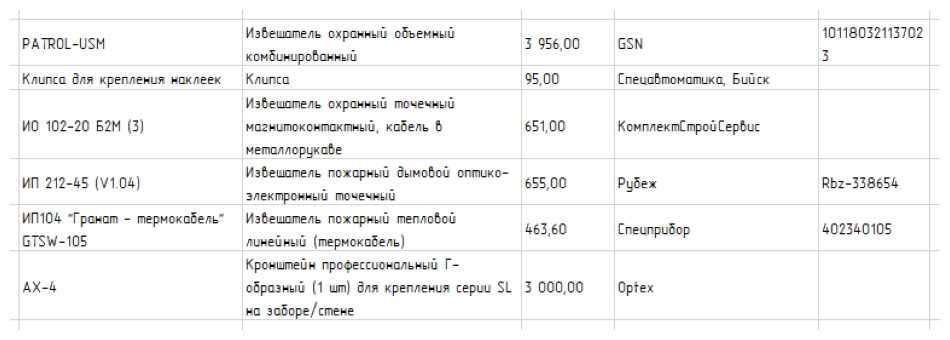

Изображение с обнаруженной таблицей:


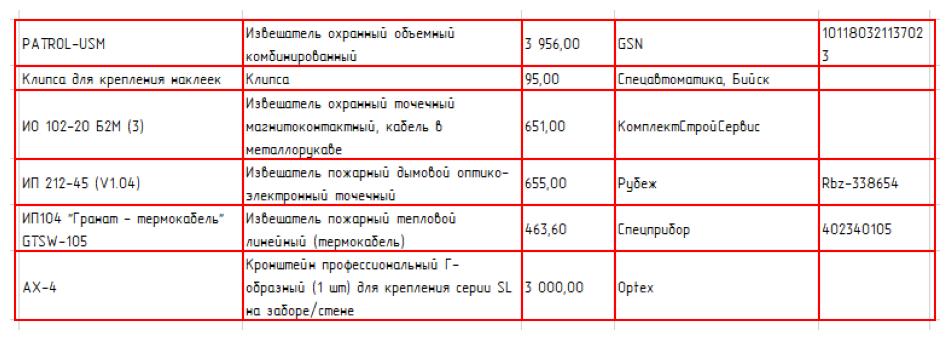

Распознанная таблица сохранена в ./results_1/table_3_gost_070.xlsx
Затраченное время: 0.871 секунд
Всего ошибок: 244
Точность распознавания: 0.527


,0,1,2,3,4
0,PATROL-USM,Извешалель охранный объенный\nкомбинированный,"3 956,00",GSN,3
1,Knunca для крепления наклеек,None,"95,00",Buick,None
2,ИО 102-20 Б2М (3),Извешалель охранный почечный\nкобель 6,"651,00",None,None
3,ИП 212-45,Извешалель пожарный дымовой onmuxo-\nпочечный,655.00,None,None
4,“Tpawam -\nGTSW-105,Извешалель пожарный mennotod,"463,60",CheunpuBop,402340105
5,None,профессиональный Г-\nобразный (1 un) для крепления cepuu SL\nна,3 000.00,Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_160.png


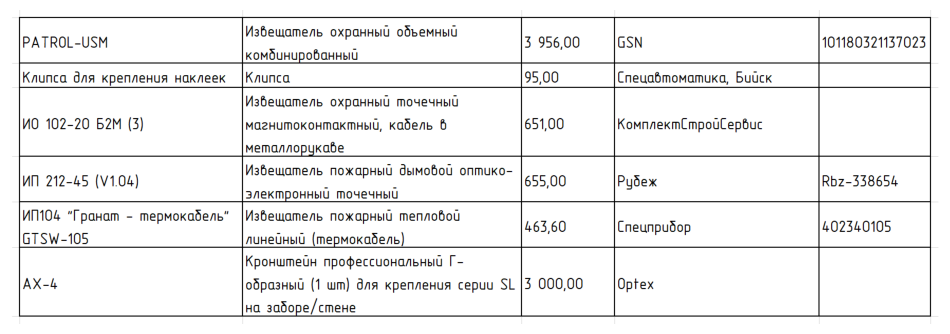

Изображение с обнаруженной таблицей:


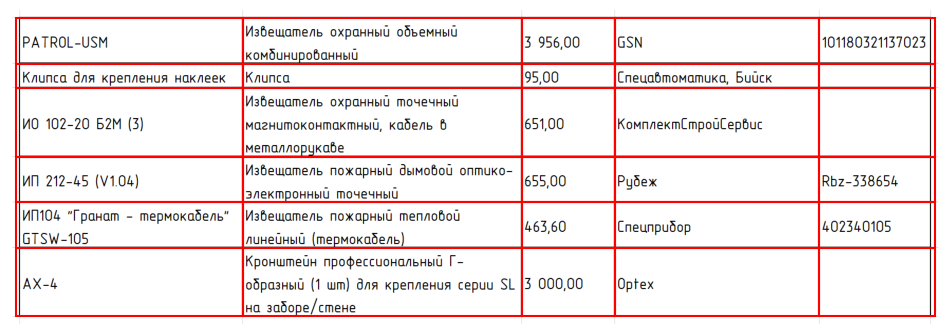

Распознанная таблица сохранена в ./results_1/table_3_gost_contrast_160.xlsx
Затраченное время: 1.266 секунд
Всего ошибок: 108
Точность распознавания: 0.791


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбиниробанный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00",Бийск,None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кобель 6\nMemannopykabe","651,00",None,None
3,ИП 212-45 (V1.04),пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
4,"""Гранат - термокабель”\nGTSW-105",Извещатель пожарный\nлинейный (термокабель),"463,60",Cneunpudop,402340105
5,AX-4,профессиональный Г-\nобразный (1 wm) для крепления cepuu SL\nна заборе/стене,"|5 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_130.png


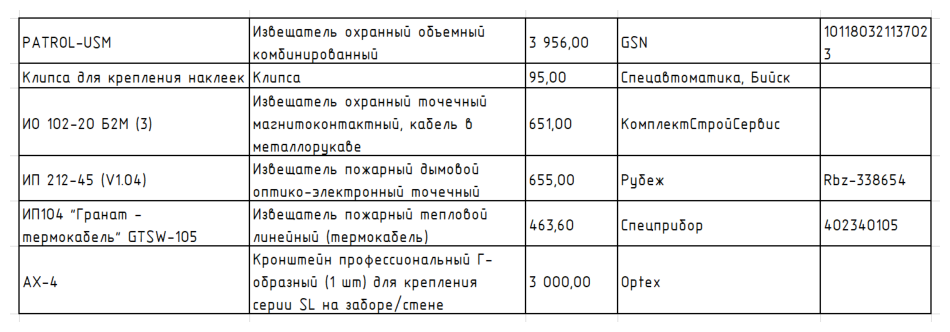

Изображение с обнаруженной таблицей:


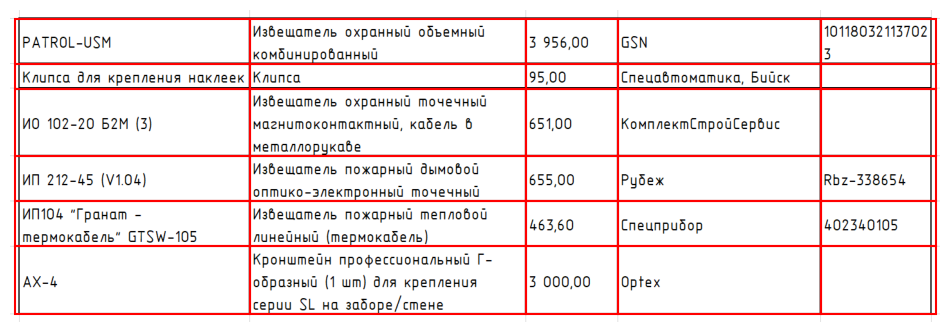

Распознанная таблица сохранена в ./results_1/table_3_gost_contrast_130.xlsx
Затраченное время: 1.320 секунд
Всего ошибок: 143
Точность распознавания: 0.723


,0,1,2,3,4
0,PATROL-USM,охранный объемный\nкомбинированный,"3 956,00",GSN,10118032113702\n3
1,Kaunca для крепления наклеек,Kaunca,"95,00","(пецабтоматика, Бийск",None
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6\nMemannopykabe","651,00",KomnaexmCmpouCepbuc,None
3,ИП 212-45 (V1.04),пожарный deimobou\nоптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"""Гранат -\nmepmokadenb” GTSW-105",пожарный тепловой\nлинебный (термокабель),"463,60",Cneunpudop,402340105
5,AX-4,Кронштейн профессиональный Г-\nобразный (1 шт) для крепления\ncepuu на sadope/cmene,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_100.png


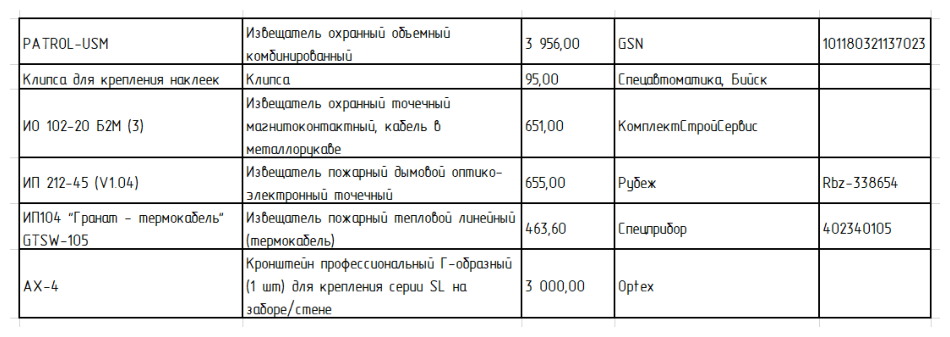

Изображение с обнаруженной таблицей:


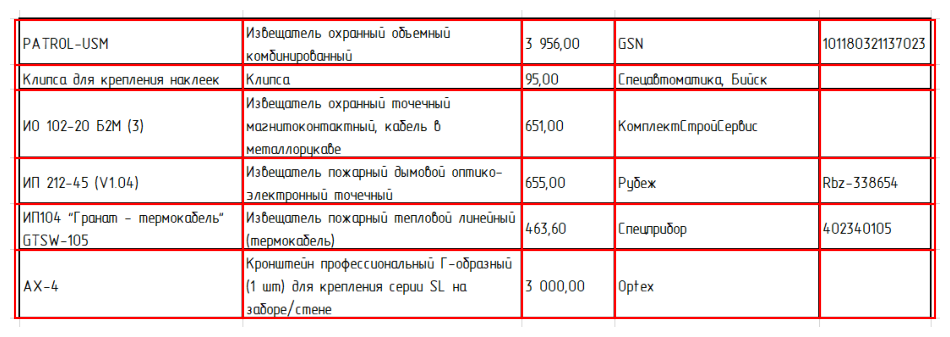

Распознанная таблица сохранена в ./results_1/table_3_gost_contrast_100.xlsx
Затраченное время: 0.998 секунд
Всего ошибок: 110
Точность распознавания: 0.787


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный\nкомбинированный,"3 956,00",GSN,101180321137023
1,для крепления наклеек,Kaunca,"95,00","Спецобтоматика,",None
2,ИО 102-20 Б2М (3),"Избещатель охранный почечный\nмагнитоконтактный, кабель 6\nметаллорцкове","651,00",None,None
3,ИП 212-45 (V1.04),Избещатель пожарный оптико-\nэлектронный почечный,"655,00",Рубех,Rbz-338654
4,-\nGTSW-105,Извещатель пожарный тепловой линебный,"463,60",None,402340105
5,АХ-&,Кронштейн профессиональные Г-образный\n(1 wm) для крепления серии на\nзаборе/стене,"3 000,00",Optex,None



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_070.png


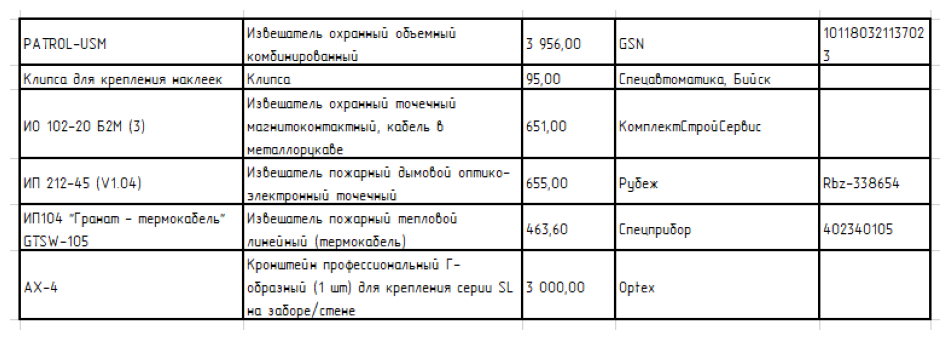

Изображение с обнаруженной таблицей:


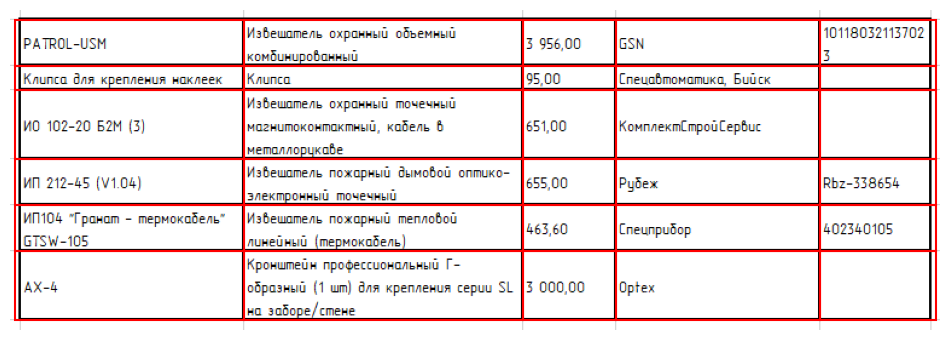

Распознанная таблица сохранена в ./results_1/table_3_gost_contrast_070.xlsx
Затраченное время: 0.904 секунд
Всего ошибок: 317
Точность распознавания: 0.386


,0,1,2,3,4
0,PATROL-USM,Извешалель охранный объенный,5 956.00,None,5
1,для крепления наклеек,None,"95,00",None,None
2,MO 102-20 Б2М (3),охранный почечный\nкобель 6,5100,None,None
3,МП 212-45,похарный onmuxo-\nпочечный,"655,00",None,None
4,-,пожарный mennotod,"463,60",None,402340105
5,None,профессиональный Г-\n(1 un) для крепления серш SL,"|3 000,00",loptex,None



----------------------------------------------------------------------------------------------------

Суммарное время распознавания 48 таблиц: 0:00:38


In [3]:
test_on_grouped_images(image_paths[:48], group_size=4, reverse=True, verbose=1, save_to_excel=True)

Изображение: ./screenshots/table_4_base_130.png


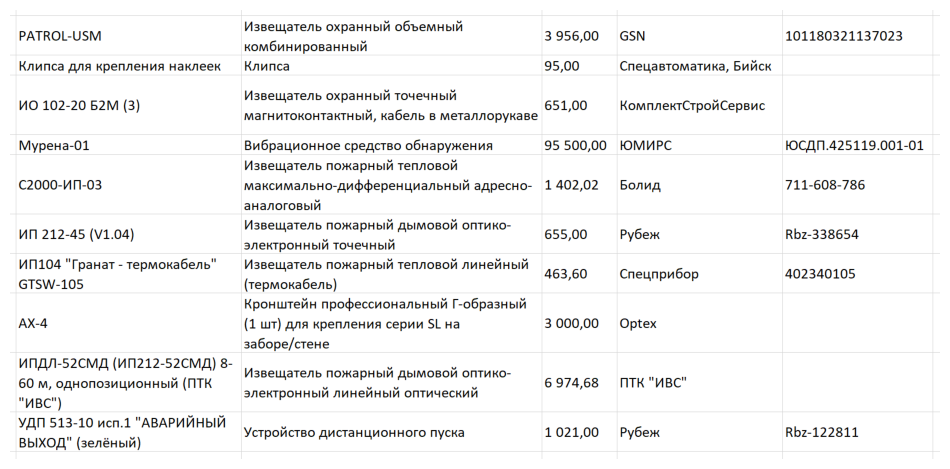

Изображение с обнаруженной таблицей:


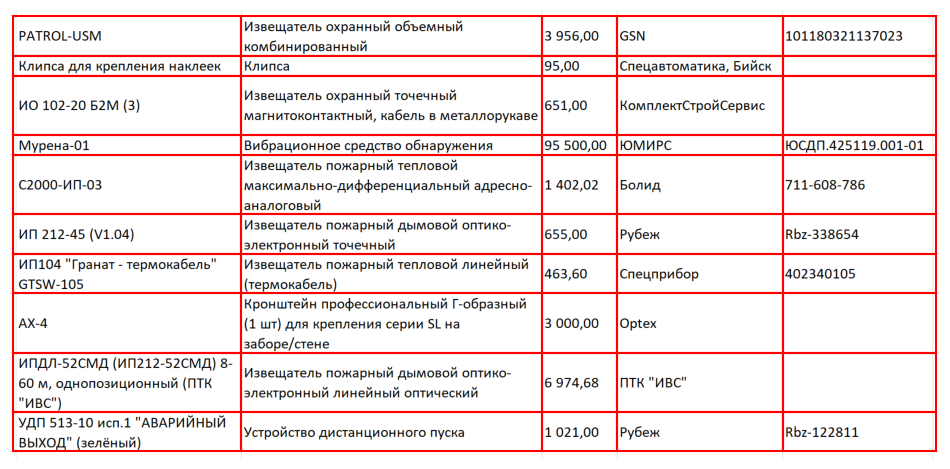

Распознанная таблица сохранена в ./results_1/table_4_base_130.xlsx
Затраченное время: 1.662 секунд
Всего ошибок: 9
Точность распознавания: 0.990


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","51,00",КомплектСтройСервис,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой\nмаксимально-дифференциальный адресно-\nаналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-\n60 м, однопозиционный (ПТК\n""VBC"")",Извещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6 974,68","NTK ""ИВС""",None
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_100.png


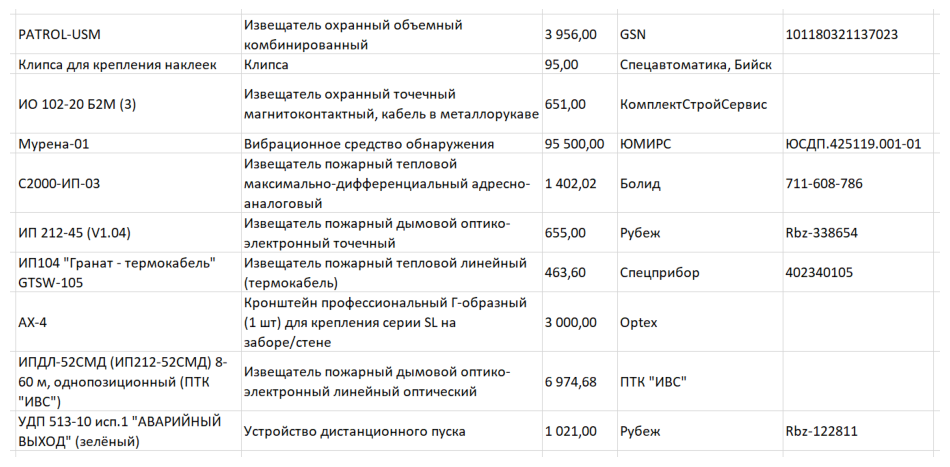

Изображение с обнаруженной таблицей:


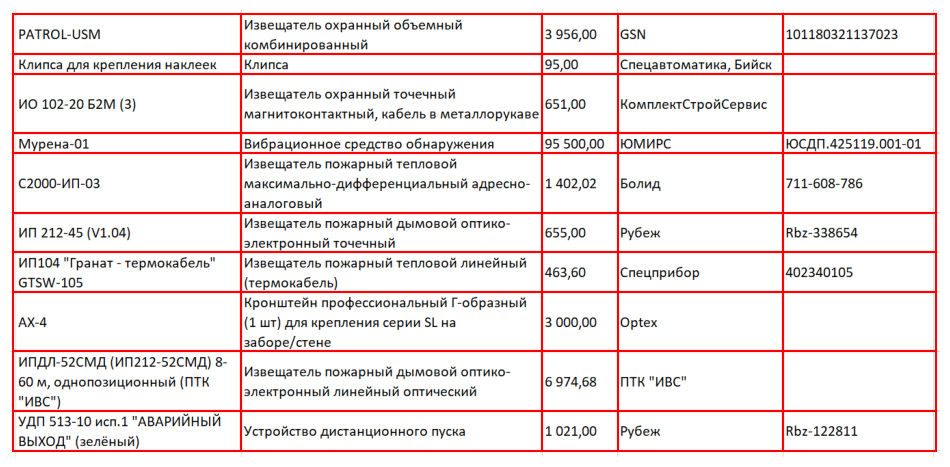

Распознанная таблица сохранена в ./results_1/table_4_base_100.xlsx
Затраченное время: 1.409 секунд
Всего ошибок: 10
Точность распознавания: 0.989


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",",00",КомплектСтройСервис,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой\nмаксимально-дифференциальный адресно-\nаналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45,Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60",Спецприбор,402340105
7,AX-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-\n60 м, однопозиционный (ПТК\n""ИВС"")",Извещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6974,68","ПТК ""ИВС""",None
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_070.png


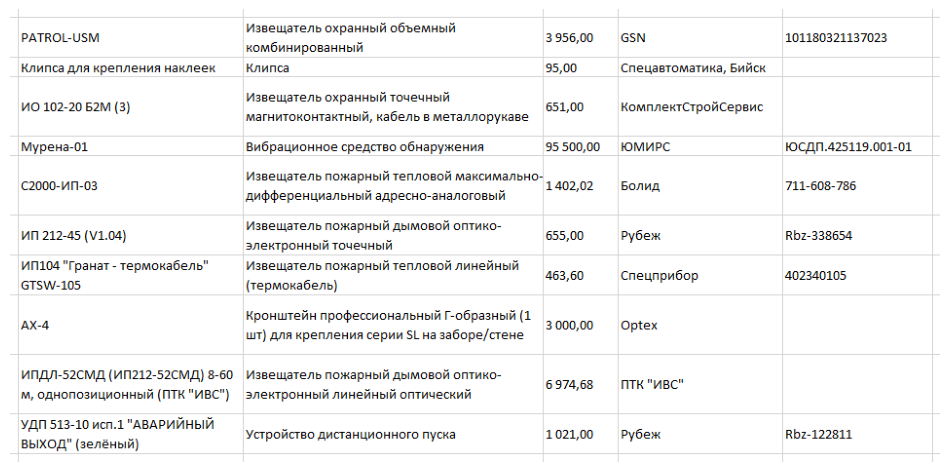

Изображение с обнаруженной таблицей:


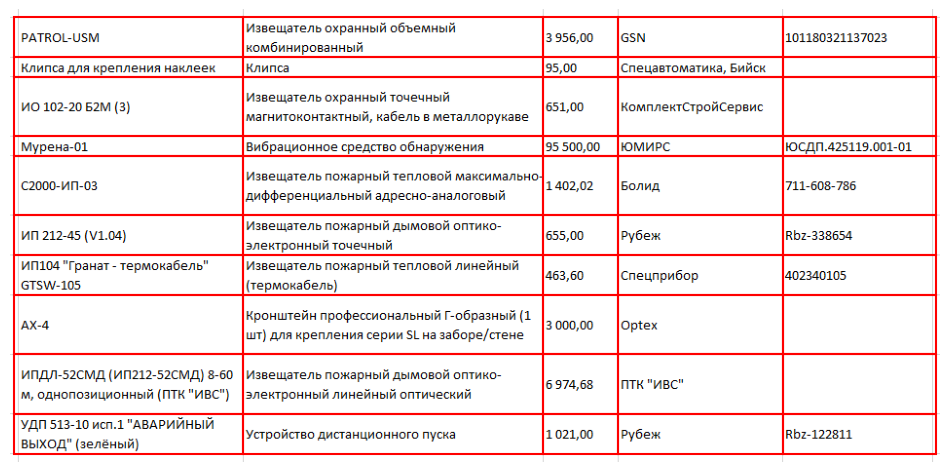

Распознанная таблица сохранена в ./results_1/table_4_base_070.xlsx
Затраченное время: 1.117 секунд
Всего ошибок: 138
Точность распознавания: 0.849


,0,1,2,3,4
0,PATROL-USM,извещатель охранный объемный\nкомбинированный,"3956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"35,00",Бийск,None
2,MMO 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",",00",Комплектстройсервис,None
3,Мурена-01,средство обнаружения,"35500,00",ЮМИРС,None
4,None,пожарный тепловой максимально-\n‘дифференциальный адресно-аналоговый,"1402,02",Болид.,711-608-786
5,ИП 212-45 (V1.04),извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00",рубеж,Rbz-338654
6,"""Гранат - термокабель""",извещатель пожарный тепловой линейный,"463,60",‘Спецприбор,402340105
7,None,Кронштейн профессиональный Г-образный (1\nшт) для крепления серии на заборе/стене,"000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60\nоднопозиционный (ПТК ""ИВС""",извещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6974,68.",None,None
9,"УДП 513-10 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_130.png


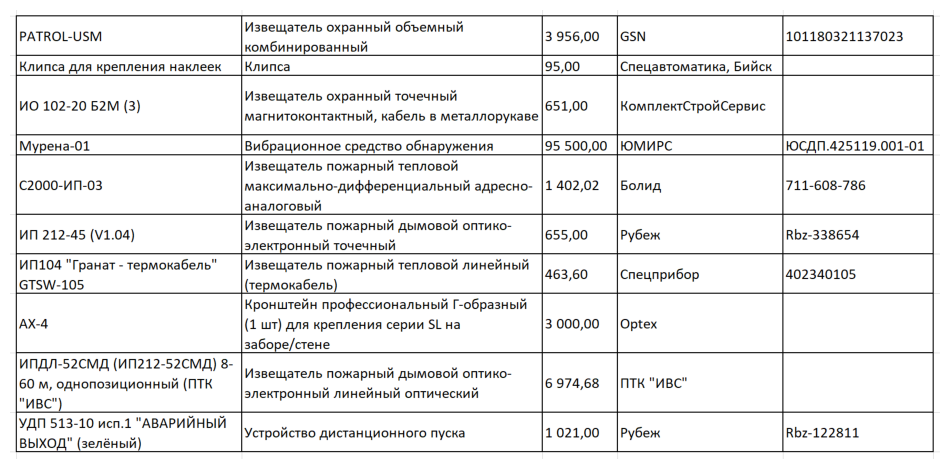

Изображение с обнаруженной таблицей:


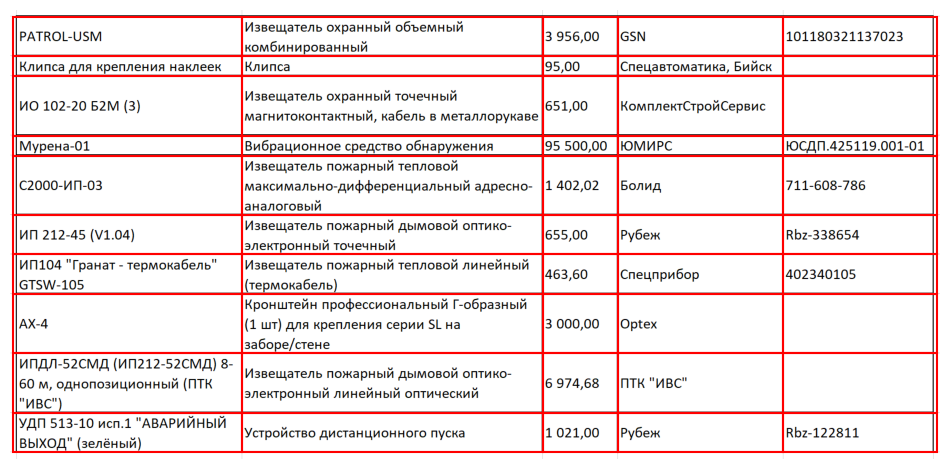

Распознанная таблица сохранена в ./results_1/table_4_base_contrast_130.xlsx
Затраченное время: 1.642 секунд
Всего ошибок: 9
Точность распознавания: 0.990


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","51,00",КомплектСтройСервис,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой\nмаксимально-дифференциальный адресно-\nаналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-\n60 м, однопозиционный (ПТК\n""VBC"")",Извещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6 974,68","NTK ""ИВС""",None
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_100.png


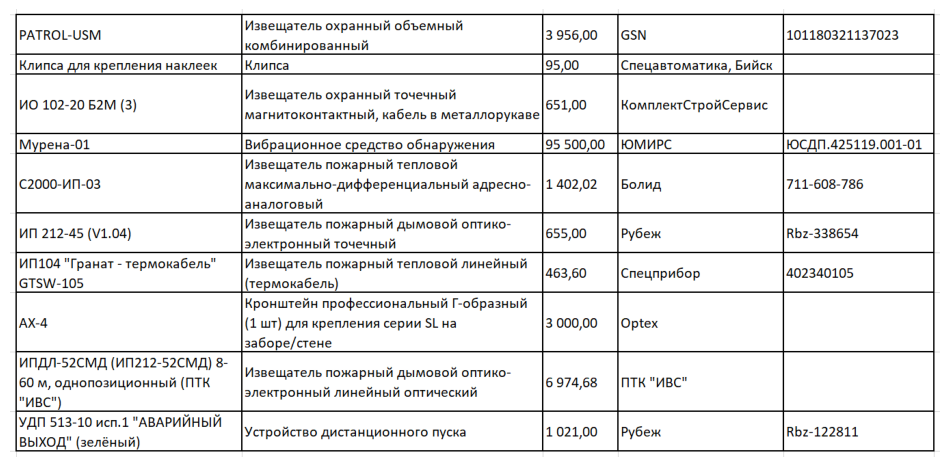

Изображение с обнаруженной таблицей:


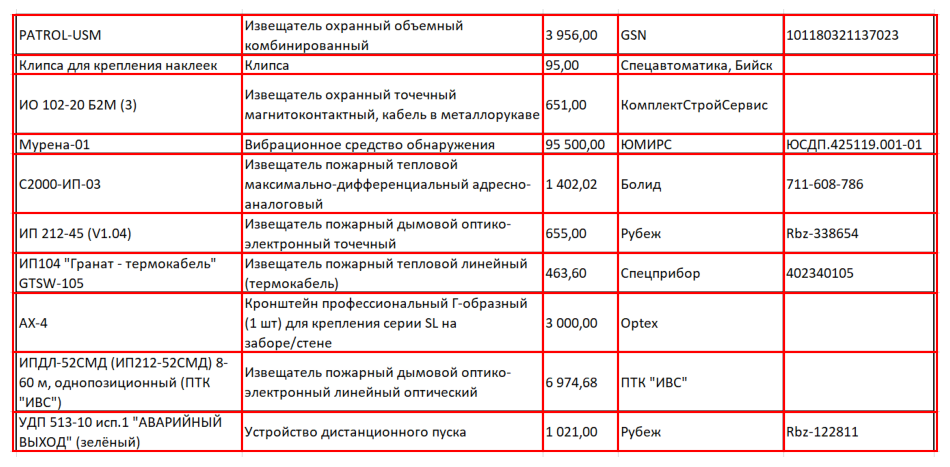

Распознанная таблица сохранена в ./results_1/table_4_base_contrast_100.xlsx
Затраченное время: 1.402 секунд
Всего ошибок: 6
Точность распознавания: 0.993


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",None
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве",‚00,КомплектСтройСервис,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой\nмаксимально-дифференциальный адресно-\nаналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель""\nGTSW-105",Извещатель пожарный тепловой линейный\n(термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный\n(1 шт) для крепления серии SL на\nзаборе/стене,"3000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-\n60 м, однопозиционный (ПТК\n""ИВС"")",Извещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6974,68","ПТК ""ИВС""",None
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_070.png


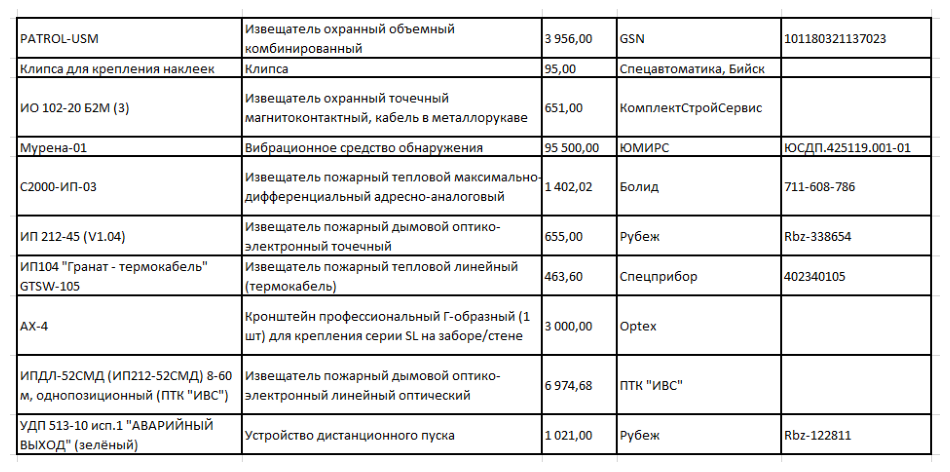

Изображение с обнаруженной таблицей:


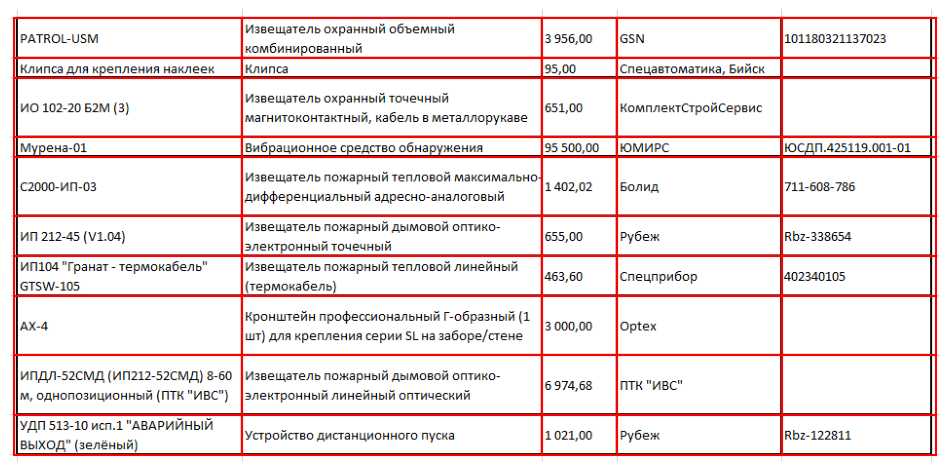

Распознанная таблица сохранена в ./results_1/table_4_base_contrast_070.xlsx
Затраченное время: 1.270 секунд
Всего ошибок: 285
Точность распознавания: 0.688


,0,1,2,3,4
0,PATROL-USM,охранный объемный,"3 956,00",None,101180321137023
1,[Клипса для крепления наклеек,None,"195,00,","[Спецавтоматика, Бийск",None
2,102-20 62M (3),охранный точечный\nкабель в металлорукаве,"651,00",Комплектстройсервис,None
3,None,[Вибрационное средство обнаружения,"[95 500,00",[ЮМИРС,None
4,None,пожарный тепловой\nадресно-аналоговый,"1402,02.",None,711-608-786
5,212-45 (У1.04),Извещатель пожарный дымовой оптико-\nточечный,"655,00",Рубеж,Rb2-338654
6,"""Гранат - термокабель""",пожарный тепловой линейный\n(repmoxaGens),"[463,60",None,[402340105
7,None,Кронштейн профессиональный Г-образный (1\nlu) для крепления серии SL на заборе/стене,"3000,00",Optex,None
8,"(ИП212-52СМД) 8-60\nоднопозиционный (ПТК ""ИВС"")",извещатель пожарный дымовой оптико-\nлинейный оптический,"6374,68",None,None
9,"Удп 513-10\nВЫХОД"" (зелёный)",дистанционного пуска,"1021,00",Рубеж,Rb2-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_130.png


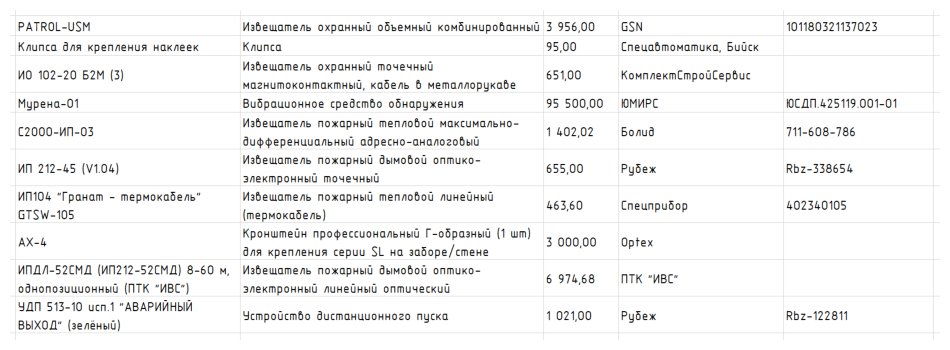

Изображение с обнаруженной таблицей:


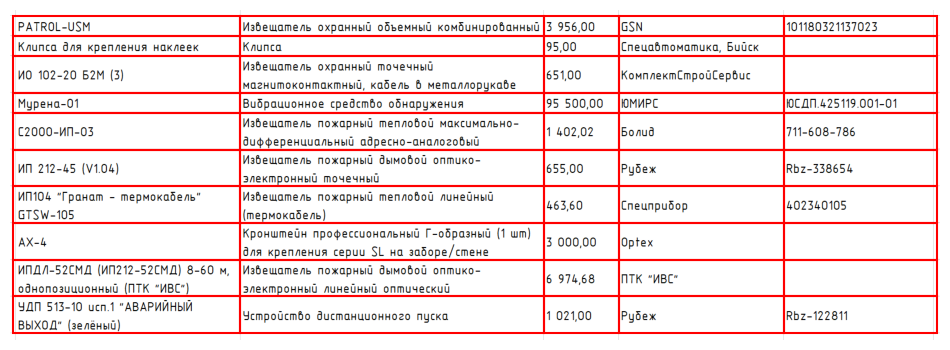

Распознанная таблица сохранена в ./results_1/table_4_gost_130.xlsx
Затраченное время: 1.786 секунд
Всего ошибок: 163
Точность распознавания: 0.821


,0,1,2,3,4
0,PATROL-USM,охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","(пецабтоматика, Бийск",None
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6","651,00",None,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,None
4,(2000-ИП-03,пожарный тепловой максимально-\nдифференциальный абресно-аналоговый,"1 402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),пожарный дымовой оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,ИП1О4 “Гранат - термокабель”\nGTSW-105,Избещатель пожарный тепловой линейный\n(пермокабель),"463,60",Cneunpudop,402340105
7,АХ-4,профессиональный Г-образный (1 wm)\ndna крепления cepuu SL на,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м,\nоднопозиционный (ПТК",Избещатель пожарный дымовой оптико-\nэлектронный линейный оптический,"6 974,68",ПТК “ИВС”,None
9,"УДП 513-10 ucn.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1 021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_100.png


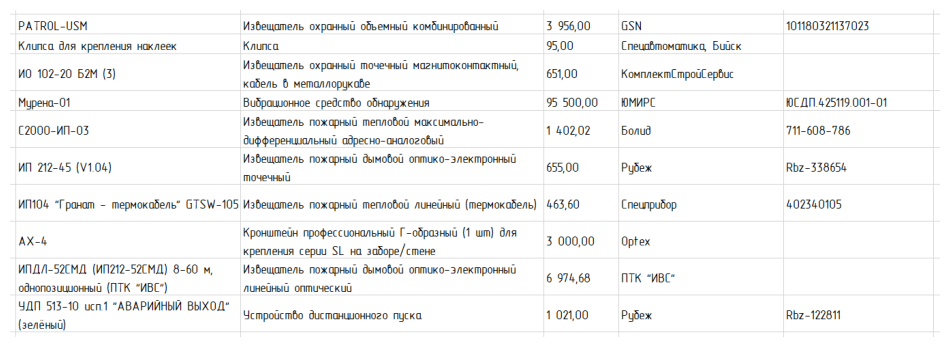

Изображение с обнаруженной таблицей:


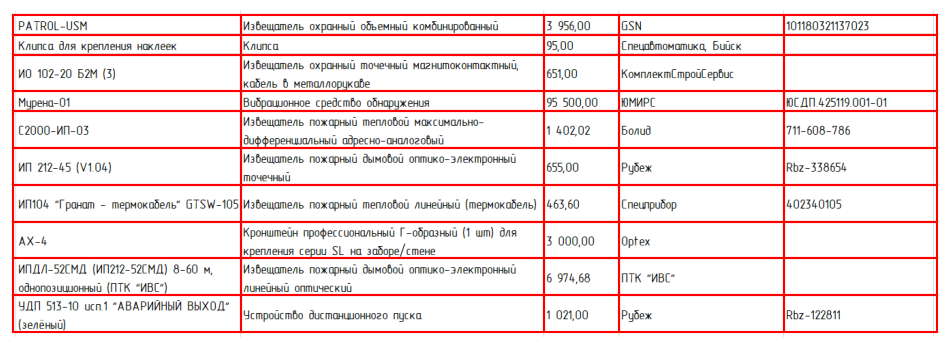

Распознанная таблица сохранена в ./results_1/table_4_gost_100.xlsx
Затраченное время: 1.396 секунд
Всего ошибок: 232
Точность распознавания: 0.746


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00",Бибск,None
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6","651,00",КомплектСтровСербис,None
3,Мурена-01,средстбо обнаружения,"95 500,00",ЮМИРС,001-01
4,None,Избещатель пожарный теплобоб максимально-,1402.02,Болид,None
5,ИП 212-45 (V1.04),Избещатель пожарный\nпочечный,"655,00",Рубех,Rbz-338654
6,“Гранал - GTSW-105,Извещатель пожарный тепловой линебный (пермокобель),"463,60",None,402340105
7,АХ-&,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии SL на заборе/стене,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м,\nоднопозищионный (ПТК",Избещатель пожарный оптико-злектронный\nлинебный оптический,"6 974,68","ПТК ""ИВС""",None
9,"YAN 513-10 “АВАРИЙНЫЙ ВЫХОД""\n(зелёный)",Устробство пуска,"1021,00",Рубех,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_070.png


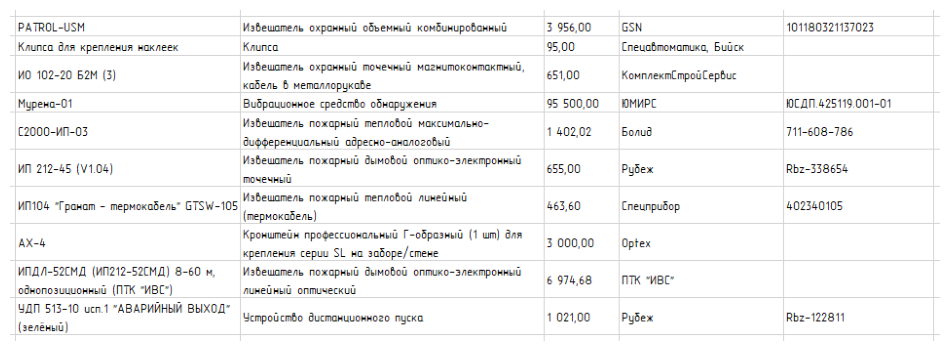

Изображение с обнаруженной таблицей:


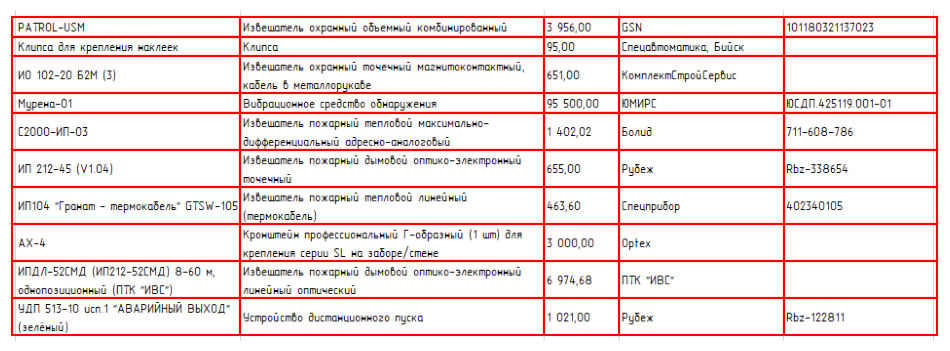

Распознанная таблица сохранена в ./results_1/table_4_gost_070.xlsx
Затраченное время: 1.223 секунд
Всего ошибок: 435
Точность распознавания: 0.524


,0,1,2,3,4
0,PATROL-USM,Извешалель охранный объенный комбинированный,"3 956,00",GSN,101180321137023
1,Knunca для крепления наклеек,Knunca,"95,00",Buick,None
2,ИО 102-20 52M (3),Извешалель охранный почечный\nкобель 8,"651,00",None,None
3,None,cpedcmbo,$5 500.00,None,None
4,None,Извешалель похарный пелловоб максимально\nдифференциальный,1402.02,Bond,711-608-786
5,ИП 212-45,Извешалель пожарный дымовой\nпочечный,655.00,None,None
6,- пермокабель” GTSW-105,Извешалель пожарный mennotod линейный,"463,60",CheunpuBop,402340105
7,None,Кронштейн профессионольнй Г-образный (1 um) для\nкрепления SL na,"3 000,00",Optex,None
8,"(ИП212-52СМД) 8-60 м,\n(ПТК",Извешалель дымовой,"6 974,68",TK “ИВС”,None
9,"YAN 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД""\n(зелёный)",пуска,1102100,None,Rb2-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_130.png


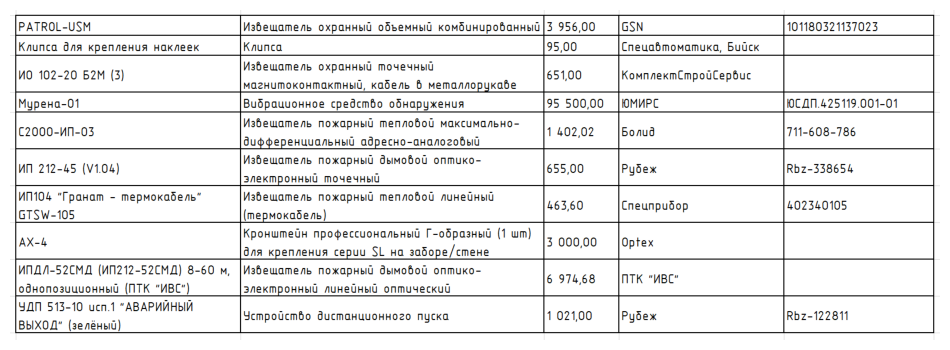

Изображение с обнаруженной таблицей:


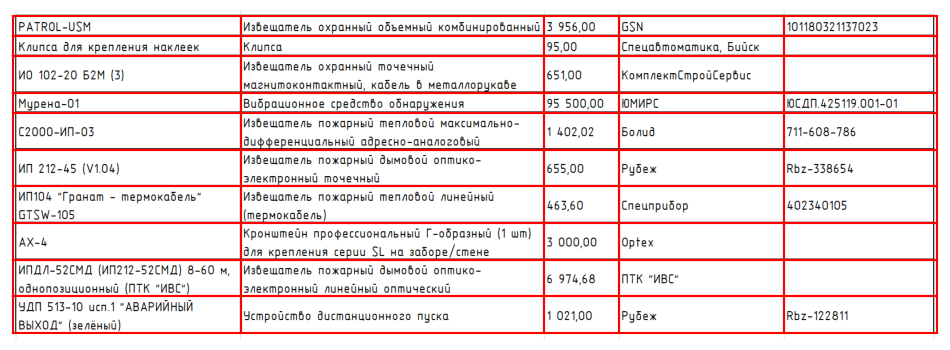

Распознанная таблица сохранена в ./results_1/table_4_gost_contrast_130.xlsx
Затраченное время: 1.686 секунд
Всего ошибок: 186
Точность распознавания: 0.796


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|5 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","(пецабтоматика, Бийск",None
2,MO 102-20 Б2М (3),"охранный точечный\nмагнитоконтактный, кабель 6 Memannopykabe","651,00",KomnaexmCmpouCepbuc,None
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,None
4,None,пожарный тепловой максимально-\nдифференциальный,"1 402,02",None,711-608-786
5,ИП 212-45 (V1.04),Избещатель пожарный оптико-\nэлектронный точечный,"655,00",Рубеж,Rbz-338654
6,"""Гранат - термокабель”\nGTSW-105",пожарный линейный\n(пермокабель),"463,60",Cneunpudop,402340105
7,AX-4,Кронштейн профессиональный Г-образный (1 wm)\nдля крепления cepuu SL на заборе/стене,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м,\nоднопозиционный",Избещатель пожарный оптико-\nэлектронный линейный оптический,"6 974,68","ПТК ""ИВС""",None
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ\nВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1 021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_100.png


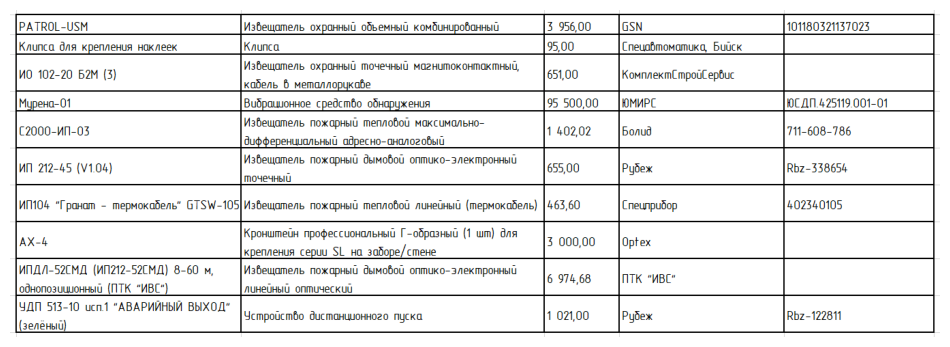

Изображение с обнаруженной таблицей:


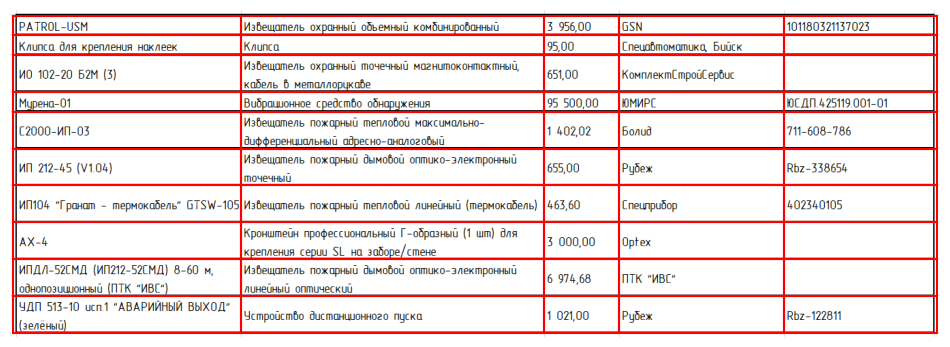

Распознанная таблица сохранена в ./results_1/table_4_gost_contrast_100.xlsx
Затраченное время: 1.564 секунд
Всего ошибок: 255
Точность распознавания: 0.721


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00",GSN,101180321137023
1,для крепления наклеек,Kaunca,"95,00","Спецобтоматика,",None
2,ИО 102-20 Б2М (3),Избещатель охранный точечный\nкабель 6 метоллорцкаве,"651,00",КомплектСтровСербис,None
3,Мурено-01,cpedcmbo обнаружения,"95 500,00",ЮМИРС,001-01
4,None,Избещатель пожарный теплобоб максимально-,"1 402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Избещатель пожарный дымовой оптико-злектронный\nточечный,"655,00",Рубех,Rbz-338654
6,“Гранал -,Извещатель пожарный тепловой линебный (пермокобель),"463,60",None,402340105
7,AX-4&,Кронштейн профессиональный Г-образный (1 wm) для\nкрепления серии SL_Ha 3adope/cmexe,"3 000,00",Optex,None
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м,",Избещатель пожарный дымовой оптико-злектронный,"974,68","ПТК ""ИВС""",None
9,"YAN 513-10 ""АВАРИЙНЫЙ ВЫХОД""\n(зелёный)",Устробство пуска,"1 021,00",Рубех,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_070.png


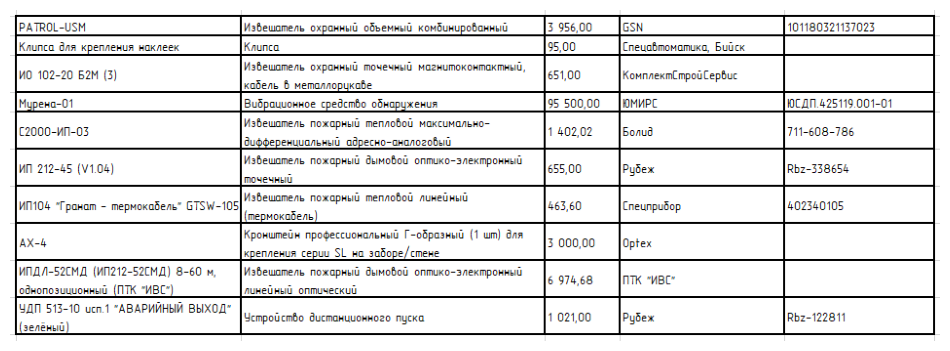

Изображение с обнаруженной таблицей:


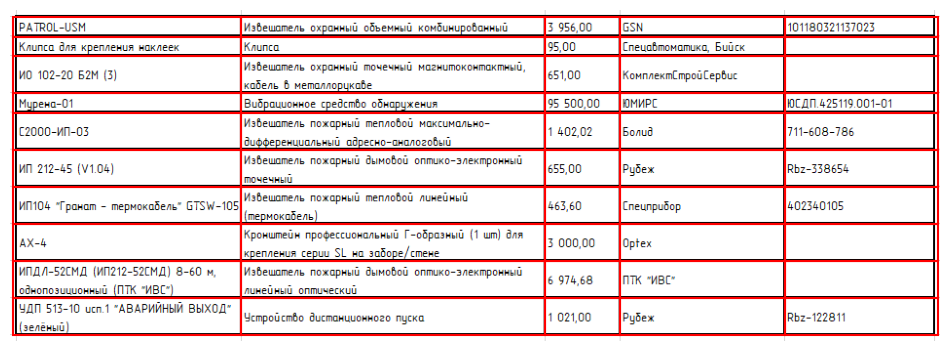

Распознанная таблица сохранена в ./results_1/table_4_gost_contrast_070.xlsx
Затраченное время: 1.239 секунд
Всего ошибок: 565
Точность распознавания: 0.381


,0,1,2,3,4
0,PATROL-USM,[Извешалель охранный объемный,"5 956,00",GSN,None
1,для крепления наклеек,Knunca,"95,00",Бийск,None
2,Мо 102-20 (3),Извешалель охранный почечный\n[кобель 6,5100,None,None
3,None,средство,95 500.00,None,42511
4,None,похарный пелловоб,"1 402,02",None,None
5,212-45,Извешалель дымовой\n[почечный,"655,00",None,None
6,- пермокабель” GTSW-105|,mennotod линейный,"463,60",None,402340105
7,None,Г-образный (1 wn) для\ncepuu SL xa,"3 000,00",loptex,None
8,"(ИП212-52СМД) 8-60 м,\n(ПТК",дымовой,"6 974,68",“ИВС”,None
9,"YAN 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД""",|Чспробство пуска,"1 021,00",None,Rb2-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_130.png


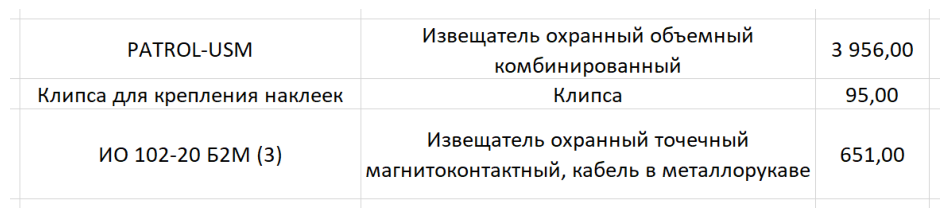

Изображение с обнаруженной таблицей:


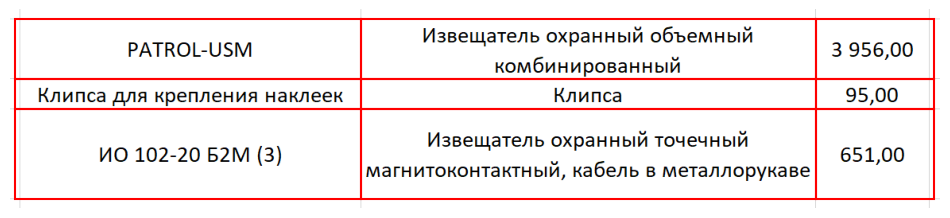

Распознанная таблица сохранена в ./results_1/table_5_base_130.xlsx
Затраченное время: 0.481 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_100.png


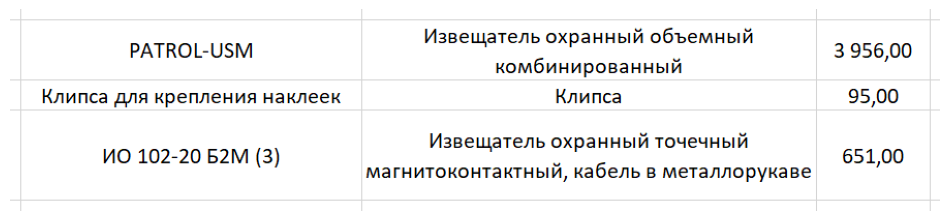

Изображение с обнаруженной таблицей:


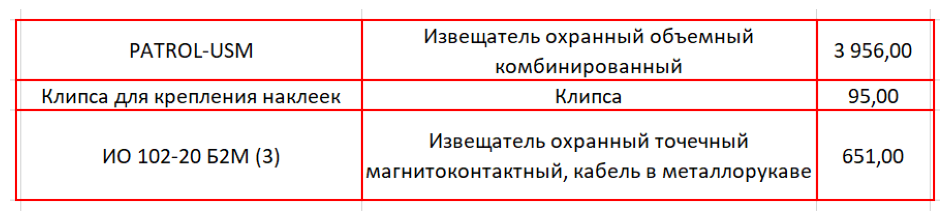

Распознанная таблица сохранена в ./results_1/table_5_base_100.xlsx
Затраченное время: 0.433 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_070.png


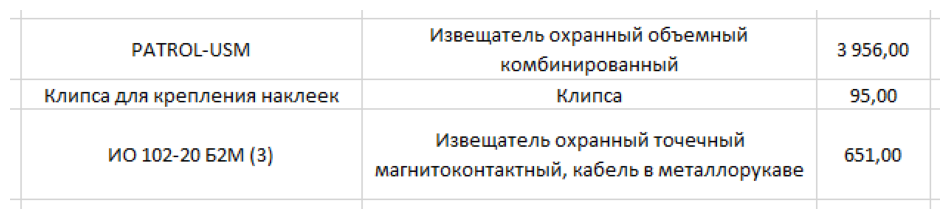

Изображение с обнаруженной таблицей:


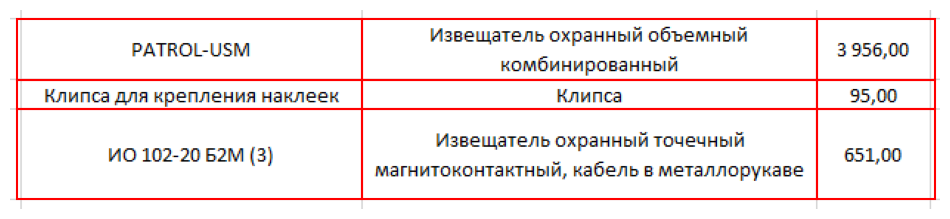

Распознанная таблица сохранена в ./results_1/table_5_base_070.xlsx
Затраченное время: 0.408 секунд
Всего ошибок: 15
Точность распознавания: 0.916


,0,1,2
0,PATROL-USM,извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,None,"35,00"
2,Mo 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","1,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_130.png


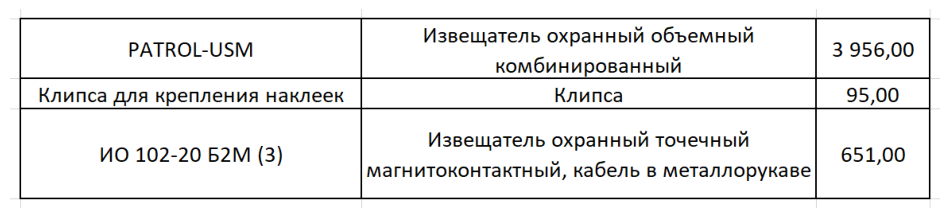

Изображение с обнаруженной таблицей:


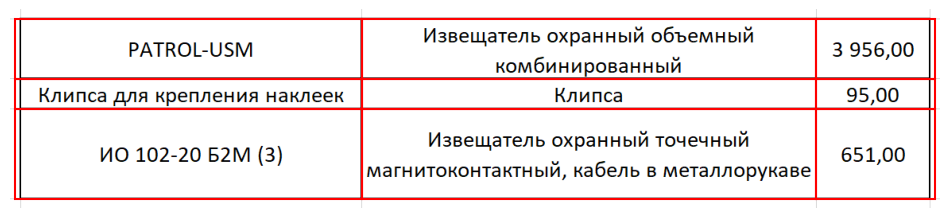

Распознанная таблица сохранена в ./results_1/table_5_base_contrast_130.xlsx
Затраченное время: 0.442 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_100.png


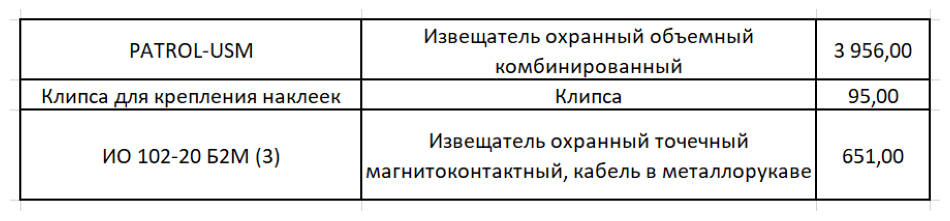

Изображение с обнаруженной таблицей:


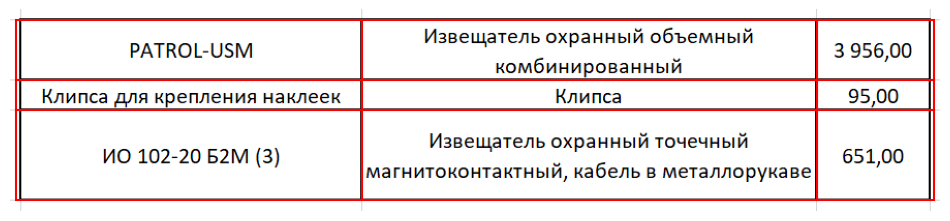

Распознанная таблица сохранена в ./results_1/table_5_base_contrast_100.xlsx
Затраченное время: 0.453 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_070.png


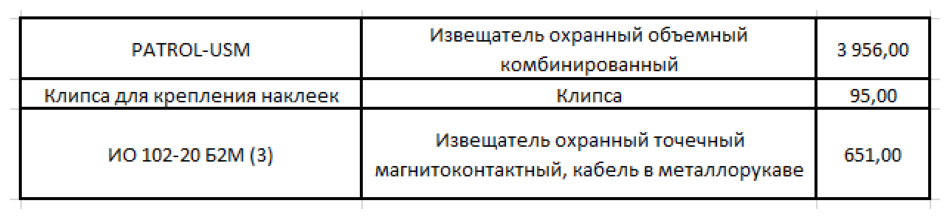

Изображение с обнаруженной таблицей:


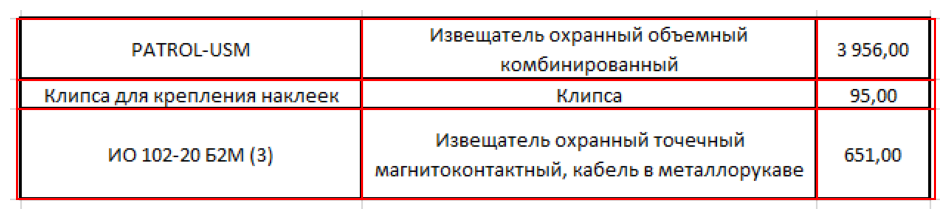

Распознанная таблица сохранена в ./results_1/table_5_base_contrast_070.xlsx
Затраченное время: 0.492 секунд
Всего ошибок: 22
Точность распознавания: 0.876


,0,1,2
0,PATROL-USM,охранный объемный\nкомбинированный,"3956,00"
1,Клипса для крепления наклеек,None,"95,00,"
2,Mo 102-20 52M (3),"извещатель охранный точечный\nмагнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_130.png


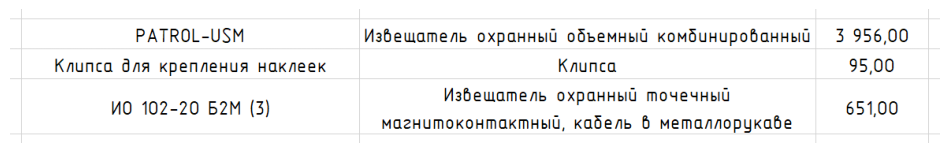

Изображение с обнаруженной таблицей:


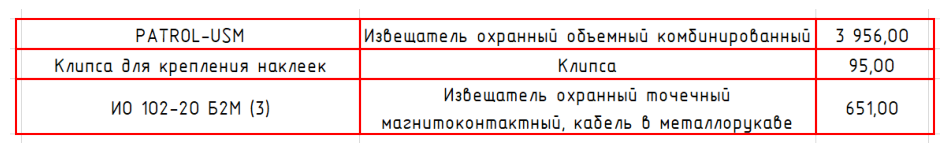

Распознанная таблица сохранена в ./results_1/table_5_gost_130.xlsx
Затраченное время: 0.552 секунд
Всего ошибок: 37
Точность распознавания: 0.792


,0,1,2
0,PATROL-USM,охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"охранный точечный\nмагнитоконтактный, кабель 6 mMemannopyKabe","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_100.png


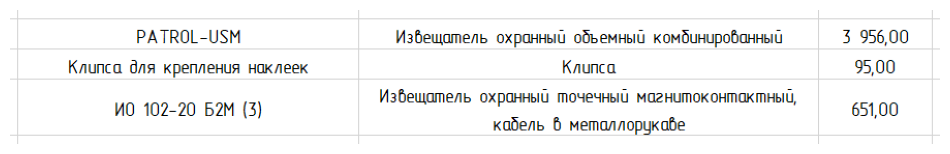

Изображение с обнаруженной таблицей:


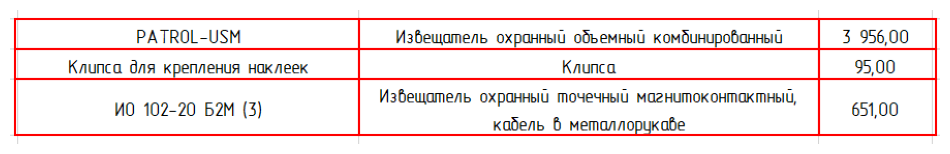

Распознанная таблица сохранена в ./results_1/table_5_gost_100.xlsx
Затраченное время: 0.486 секунд
Всего ошибок: 23
Точность распознавания: 0.871


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 Memannopykabe","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_070.png


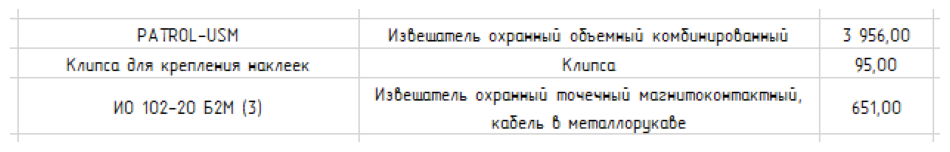

Изображение с обнаруженной таблицей:


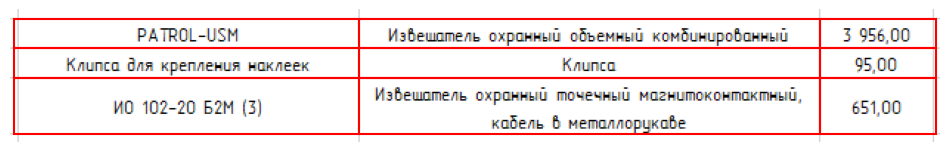

Распознанная таблица сохранена в ./results_1/table_5_gost_070.xlsx
Затраченное время: 0.404 секунд
Всего ошибок: 41
Точность распознавания: 0.770


,0,1,2
0,PATROL-USM,Извешалель охранный объенный комбинированный,3956.00
1,Knunca для крепления наклеек,None,"95,00"
2,ИО 102-20 52M (3),Извешалель охранный почечный могнитоконлеклный\nкобель 8 memannopyxabe,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_130.png


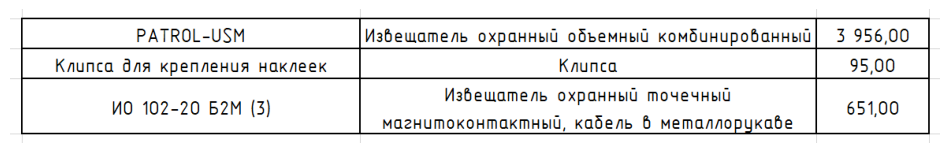

Изображение с обнаруженной таблицей:


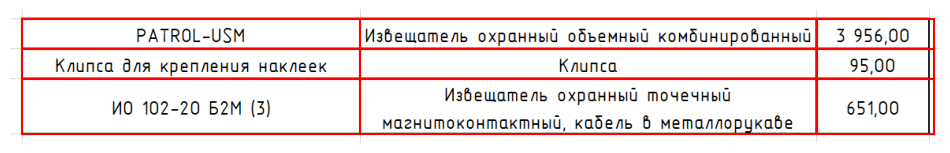

Распознанная таблица сохранена в ./results_1/table_5_gost_contrast_130.xlsx
Затраченное время: 0.532 секунд
Всего ошибок: 60
Точность распознавания: 0.663


,0,1,2
0,PATROL-USM,охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,MO 102-20 Б2М (3),охранный точечный\nкабель 6 Memannopykabe,"651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_100.png


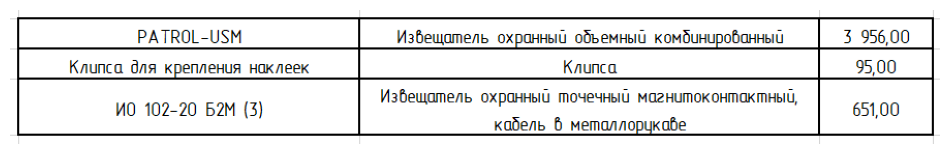

Изображение с обнаруженной таблицей:


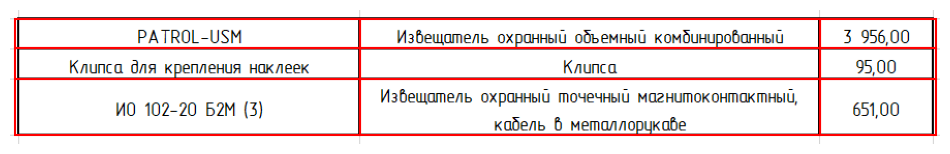

Распознанная таблица сохранена в ./results_1/table_5_gost_contrast_100.xlsx
Затраченное время: 0.565 секунд
Всего ошибок: 21
Точность распознавания: 0.882


,0,1,2
0,PATROL-USM,Vsbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный,\nкабель 6 метоллорцкаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_070.png


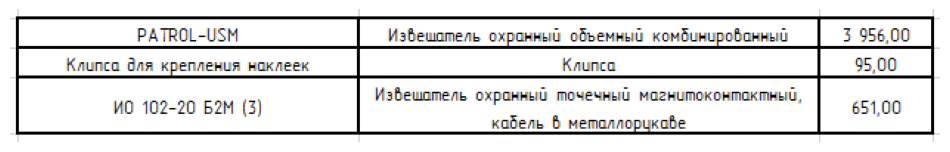

Изображение с обнаруженной таблицей:


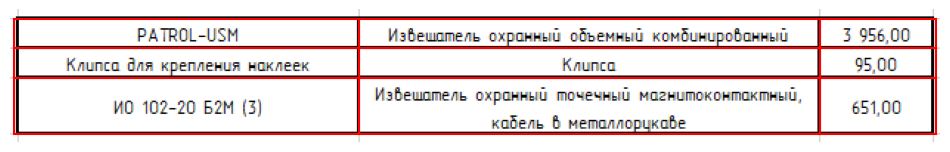

Распознанная таблица сохранена в ./results_1/table_5_gost_contrast_070.xlsx
Затраченное время: 0.479 секунд
Всего ошибок: 69
Точность распознавания: 0.612


,0,1,2
0,PATROL-USM,Извешалель охранный объемный,3956.00
1,Knunca для крепления наклеек,Knunca,"95,00"
2,WO 102-20 B2M (3),Извешалель охранный почечный\nкобель 6,"651,00"



----------------------------------------------------------------------------------------------------

Суммарное время распознавания 24 таблиц: 0:00:23


In [4]:
test_on_grouped_images(image_paths[48:72], group_size=3, reverse=True, verbose=1, save_to_excel=True)